# Data Preprocessing - Earliest Duplicate Kept

This notebook is a modified version of the original preprocessing pipeline, where the duplicate-review retention policy has been changed. The original implementation retained the **most recent** interaction for each duplicated user–product pair, reproducing the official Amazon Reviews 2023 Electronics benchmark with approximately **99.8%** agreement. To reproduce the benchmark as closely as possible, the duplicate-resolution step has been modified to retain the **earliest** interaction instead, matching the policy described by the dataset authors. Only the preprocessing stages following duplicate resolution are rerun.

This notebook transforms the raw Amazon Electronics review and metadata datasets into clean and structured datasets suitable for recommendation modelling.

The preprocessing pipeline will:

1. identify and remove invalid interactions;
2. select minimum user and product activity thresholds;
3. iteratively filter inactive users and products;
4. resolve duplicate user–product interactions by retaining the earliest review;
5. clean the selected product metadata fields;
6. encode user and product identifiers as integer indices; and
7. save the processed interactions, metadata, and identifier mappings.

The train, validation, and test sets will not be created in this notebook. Temporal data splitting will be performed separately after preprocessing.

## 1. Setup
## 1.1 Imports

In [29]:
import gzip
import json
import pickle
import time

from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1.2 File paths

In [27]:
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

REVIEWS_PATH = RAW_DIR / "Electronics.jsonl.gz"
METADATA_PATH = RAW_DIR / "meta_Electronics.jsonl.gz"

REVIEW_STATISTICS_PATH = PROCESSED_DIR / "dataset_statistics.pkl"
METADATA_EXPLORATION_PATH = PROCESSED_DIR / "metadata_exploration.pkl"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    REVIEWS_PATH,
    METADATA_PATH,
    REVIEW_STATISTICS_PATH,
    METADATA_EXPLORATION_PATH,
]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

print("All required files were found.")

All required files were found.


## 2. Activity Analysis and threshold selection

### 2.1 Load Cached Review Statistics

The review statistics generated in the first notebook are reused to analyse user and product activity. Reusing the cached results avoids performing another complete scan of the approximately 44 million raw interactions.

In [3]:
with open(REVIEW_STATISTICS_PATH, "rb") as file:
    review_statistics = pickle.load(file)

total_reviews = review_statistics["total_reviews"]
user_activity = review_statistics["user_activity"]
product_activity = review_statistics["product_activity"]

print(f"Total interactions: {total_reviews:,}")
print(f"Unique users: {len(user_activity):,}")
print(f"Unique products: {len(product_activity):,}")

Total interactions: 43,886,944
Unique users: 18,286,191
Unique products: 1,609,860


### 2.2 User and Product Activity Analysis

Users and products with very few interactions provide limited collaborative information and increase the sparsity of the user–item graph. Activity thresholds are therefore evaluated before filtering the dataset.

At this stage, user and product retention are calculated independently. The exact number of interactions retained after applying both conditions will be determined during the full preprocessing scan.

In [4]:
# %pip install jinja2

In [5]:
candidate_thresholds = [2, 3, 5, 10, 20]

threshold_results = []

for threshold in candidate_thresholds:
    retained_users = sum(
        interaction_count >= threshold
        for interaction_count in user_activity.values()
    )

    retained_products = sum(
        interaction_count >= threshold
        for interaction_count in product_activity.values()
    )

    interactions_from_retained_users = sum(
        interaction_count
        for interaction_count in user_activity.values()
        if interaction_count >= threshold
    )

    interactions_for_retained_products = sum(
        interaction_count
        for interaction_count in product_activity.values()
        if interaction_count >= threshold
    )

    threshold_results.append({
        "Minimum Interactions": threshold,
        "Retained Users": retained_users,
        "Users Retained (%)": retained_users / len(user_activity) * 100,
        "Retained Products": retained_products,
        "Products Retained (%)": (
            retained_products / len(product_activity) * 100
        ),
        "User-Side Interactions": interactions_from_retained_users,
        "User-Side Interaction Retention (%)": (
            interactions_from_retained_users / total_reviews * 100
        ),
        "Product-Side Interactions": interactions_for_retained_products,
        "Product-Side Interaction Retention (%)": (
            interactions_for_retained_products / total_reviews * 100
        ),
    })

threshold_summary = pd.DataFrame(threshold_results)

threshold_summary.style.format({
    "Retained Users": "{:,.0f}",
    "Users Retained (%)": "{:.2f}%",
    "Retained Products": "{:,.0f}",
    "Products Retained (%)": "{:.2f}%",
    "User-Side Interactions": "{:,.0f}",
    "User-Side Interaction Retention (%)": "{:.2f}%",
    "Product-Side Interactions": "{:,.0f}",
    "Product-Side Interaction Retention (%)": "{:.2f}%",
})

,Minimum Interactions,Retained Users,Users Retained (%),Retained Products,Products Retained (%),User-Side Interactions,User-Side Interaction Retention (%),Product-Side Interactions,Product-Side Interaction Retention (%)
0,2,"7,967,473",43.57%,"1,070,016",66.47%,"33,568,226",76.49%,"43,347,100",98.77%
1,3,"4,346,823",23.77%,"846,397",52.58%,"26,326,926",59.99%,"42,899,862",97.75%
2,5,"1,881,540",10.29%,"625,507",38.85%,"18,054,706",41.14%,"42,147,970",96.04%
3,10,"538,518",2.94%,"403,258",25.05%,"9,594,541",21.86%,"40,684,398",92.70%
4,20,"130,244",0.71%,"247,421",15.37%,"4,320,134",9.84%,"38,562,181",87.87%


## 2.3 The Effect of Filtering

Before choosing a filtering threshold, it is worth seeing what each one costs. Removing
users and products with few interactions improves data quality but discards a large share
of the dataset, so the choice is a trade-off rather than an obvious win.

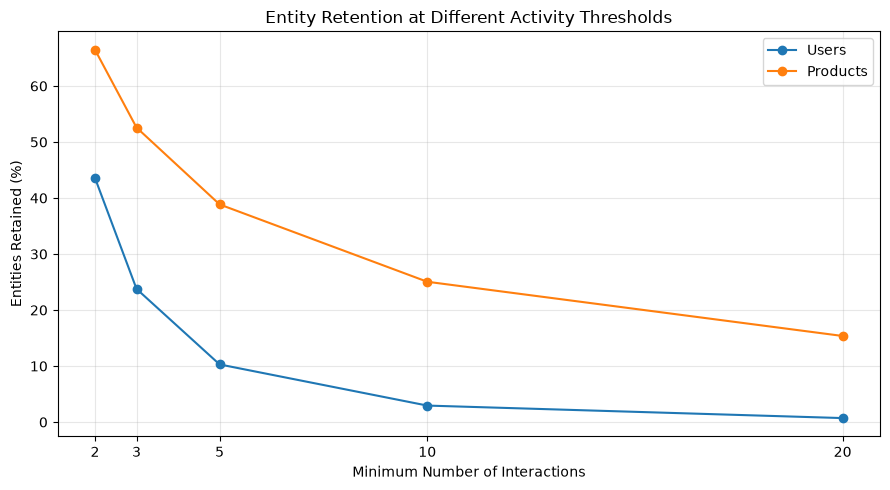

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_summary["Minimum Interactions"],
    threshold_summary["Users Retained (%)"],
    marker="o",
    label="Users"
)

plt.plot(
    threshold_summary["Minimum Interactions"],
    threshold_summary["Products Retained (%)"],
    marker="o",
    label="Products"
)

plt.title("Entity Retention at Different Activity Thresholds")
plt.xlabel("Minimum Number of Interactions")
plt.ylabel("Entities Retained (%)")
plt.xticks(candidate_thresholds)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.4 Threshold Selection

The activity analysis shows that the Amazon Electronics dataset contains a large proportion of low-activity users. Increasing the minimum interaction threshold therefore causes a substantial reduction in the number of retained users.

A minimum threshold of five interactions was selected for both users and products. At this level, approximately 10.29% of users and 38.85% of products are retained when activity is evaluated independently. The threshold provides a balance between reducing graph sparsity and preserving a sufficiently large dataset for recommendation modelling.

A threshold of two or three interactions would retain more users, but such users provide limited behavioural history for collaborative learning and temporal evaluation. In contrast, thresholds of ten or twenty interactions would remove a substantial amount of potentially useful user data.

Because user and product activity are interdependent, the final filtering stage will apply the thresholds iteratively. Filtering will continue until every retained user and product has at least five interactions within the remaining dataset.

## 3. Initial Interaction Filtering

The first filtering pass removes users and products whose activity in the raw dataset is below the selected threshold of five interactions.

Only fields required for recommendation modelling are retained:

- `user_id`: original user identifier;
- `parent_asin`: parent product identifier;
- `rating`: explicit user rating;
- `timestamp`: interaction time; and
- `verified_purchase`: indicator of whether the purchase was verified.

The filtered interactions are written incrementally to Parquet files. This avoids loading the complete review dataset into memory and creates a more efficient intermediate dataset for iterative filtering.

In [7]:
MIN_USER_INTERACTIONS = 5
MIN_PRODUCT_INTERACTIONS = 5

INTERMEDIATE_DIR = PROCESSED_DIR / "candidate_interactions"
INTERMEDIATE_DIR.mkdir(parents=True, exist_ok=True)

eligible_users = {
    user_id
    for user_id, count in user_activity.items()
    if count >= MIN_USER_INTERACTIONS
}

eligible_products = {
    parent_asin
    for parent_asin, count in product_activity.items()
    if count >= MIN_PRODUCT_INTERACTIONS
}

print(f"Initially eligible users: {len(eligible_users):,}")
print(f"Initially eligible products: {len(eligible_products):,}")

Initially eligible users: 1,881,540
Initially eligible products: 625,507


In [8]:
existing_chunks = list(INTERMEDIATE_DIR.glob("candidate_*.parquet"))

for path in existing_chunks:
    path.unlink()

print(f"Removed {len(existing_chunks)} existing candidate files.")

Removed 0 existing candidate files.


### 3.1 Stream and filter the interactions

In [9]:
import pyarrow

In [10]:
CHUNK_SIZE = 250_000
PROGRESS_INTERVAL = 1_000_000

buffer = []

total_scanned = 0
valid_interactions = 0
retained_interactions = 0

invalid_user_ids = 0
invalid_product_ids = 0
invalid_ratings = 0
invalid_timestamps = 0

chunk_number = 0
start_time = time.time()


def save_candidate_chunk(records, chunk_index):
    """Save one candidate-interaction chunk as a Parquet file."""
    
    chunk_df = pd.DataFrame.from_records(
        records,
        columns=[
            "user_id",
            "parent_asin",
            "rating",
            "timestamp",
            "verified_purchase",
        ],
    )

    output_path = (
        INTERMEDIATE_DIR /
        f"candidate_{chunk_index:04d}.parquet"
    )

    chunk_df.to_parquet(
        output_path,
        index=False,
        engine="pyarrow",
        compression="snappy",
    )

    return output_path


with gzip.open(REVIEWS_PATH, "rt", encoding="utf-8") as file:
    for line in file:
        total_scanned += 1

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            continue

        user_id = record.get("user_id")
        parent_asin = record.get("parent_asin")
        rating = record.get("rating")
        timestamp = record.get("timestamp")
        verified_purchase = record.get("verified_purchase")

        # Validate identifiers
        if not isinstance(user_id, str) or not user_id.strip():
            invalid_user_ids += 1
            continue

        if not isinstance(parent_asin, str) or not parent_asin.strip():
            invalid_product_ids += 1
            continue

        # Validate rating
        try:
            rating = float(rating)
        except (TypeError, ValueError):
            invalid_ratings += 1
            continue

        if not 1.0 <= rating <= 5.0:
            invalid_ratings += 1
            continue

        # Validate timestamp
        try:
            timestamp = int(timestamp)
        except (TypeError, ValueError):
            invalid_timestamps += 1
            continue

        if timestamp <= 0:
            invalid_timestamps += 1
            continue

        valid_interactions += 1

        # Apply initial activity filters
        if user_id not in eligible_users:
            continue

        if parent_asin not in eligible_products:
            continue

        buffer.append({
            "user_id": user_id,
            "parent_asin": parent_asin,
            "rating": rating,
            "timestamp": timestamp,
            "verified_purchase": bool(verified_purchase),
        })

        retained_interactions += 1

        if len(buffer) >= CHUNK_SIZE:
            save_candidate_chunk(buffer, chunk_number)
            chunk_number += 1
            buffer.clear()

        if total_scanned % PROGRESS_INTERVAL == 0:
            elapsed = time.time() - start_time

            print(
                f"Scanned: {total_scanned:,} | "
                f"Retained: {retained_interactions:,} | "
                f"Chunks: {chunk_number:,} | "
                f"Elapsed: {elapsed / 60:.1f} minutes"
            )

# Save the final partial chunk
if buffer:
    save_candidate_chunk(buffer, chunk_number)
    chunk_number += 1
    buffer.clear()

elapsed = time.time() - start_time

print("\nInitial filtering completed.")
print(f"Total records scanned: {total_scanned:,}")
print(f"Valid interactions: {valid_interactions:,}")
print(f"Retained interactions: {retained_interactions:,}")
print(f"Parquet chunks created: {chunk_number:,}")
print(f"Processing time: {elapsed / 60:.2f} minutes")

Scanned: 4,000,000 | Retained: 2,806,060 | Chunks: 11 | Elapsed: 0.5 minutes
Scanned: 7,000,000 | Retained: 4,724,172 | Chunks: 18 | Elapsed: 0.8 minutes
Scanned: 10,000,000 | Retained: 6,525,862 | Chunks: 26 | Elapsed: 1.1 minutes
Scanned: 13,000,000 | Retained: 8,282,980 | Chunks: 33 | Elapsed: 1.4 minutes
Scanned: 14,000,000 | Retained: 8,831,480 | Chunks: 35 | Elapsed: 1.5 minutes
Scanned: 17,000,000 | Retained: 10,287,139 | Chunks: 41 | Elapsed: 1.8 minutes
Scanned: 20,000,000 | Retained: 11,623,717 | Chunks: 46 | Elapsed: 2.2 minutes
Scanned: 21,000,000 | Retained: 12,065,354 | Chunks: 48 | Elapsed: 2.3 minutes
Scanned: 26,000,000 | Retained: 13,999,723 | Chunks: 55 | Elapsed: 2.9 minutes
Scanned: 29,000,000 | Retained: 14,950,790 | Chunks: 59 | Elapsed: 3.2 minutes
Scanned: 31,000,000 | Retained: 15,518,612 | Chunks: 62 | Elapsed: 3.4 minutes
Scanned: 34,000,000 | Retained: 16,230,145 | Chunks: 64 | Elapsed: 4.0 minutes
Scanned: 35,000,000 | Retained: 16,432,762 | Chunks: 65 | E

### 3.2 Validation summary

In [11]:
initial_filter_summary = pd.DataFrame({
    "Measure": [
        "Raw records scanned",
        "Valid interactions",
        "Retained candidate interactions",
        "Invalid user identifiers",
        "Invalid product identifiers",
        "Invalid ratings",
        "Invalid timestamps",
        "Parquet chunks created",
    ],
    "Value": [
        total_scanned,
        valid_interactions,
        retained_interactions,
        invalid_user_ids,
        invalid_product_ids,
        invalid_ratings,
        invalid_timestamps,
        chunk_number,
    ],
})

initial_filter_summary["Value"] = (
    initial_filter_summary["Value"]
    .map(lambda value: f"{value:,}")
)

display(initial_filter_summary)

,Measure,Value
0,Raw records scanned,"43,886,944"
1,Valid interactions,"43,886,942"
2,Retained candidate interactions,"17,273,814"
3,Invalid user identifiers,0
4,Invalid product identifiers,0
5,Invalid ratings,2
6,Invalid timestamps,0
7,Parquet chunks created,70


### 3.3 Verify the generated files

In [12]:
candidate_files = sorted(
    INTERMEDIATE_DIR.glob("candidate_*.parquet")
)

if not candidate_files:
    raise FileNotFoundError(
        "No candidate interaction files were created."
    )

sample_candidate_df = pd.read_parquet(candidate_files[0])

print(f"Candidate files found: {len(candidate_files):,}")
print(f"First file: {candidate_files[0].name}")
print(f"Rows in first file: {len(sample_candidate_df):,}")
print("\nColumn data types:")
print(sample_candidate_df.dtypes)

display(sample_candidate_df.head())

Candidate files found: 70
First file: candidate_0000.parquet
Rows in first file: 250,000

Column data types:
user_id                  str
parent_asin              str
rating               float64
timestamp              int64
verified_purchase       bool
dtype: object


,user_id,parent_asin,rating,timestamp,verified_purchase
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07CML419K,5.0,1637522881041,True
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07BHHB5RH,5.0,1565130879386,True
2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B09S6Y5BRG,5.0,1541356831659,True
3,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B01LW71IBJ,5.0,1456772571000,True
4,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B017T99JPG,5.0,1456772365000,True


### 3.4 Recalculate activity on the candidate dataset

The initial filtering stage selected users and products using activity counts from the complete raw dataset. However, removing low-activity entities from one side of the interaction graph may reduce the activity of entities on the other side.

User and product interaction counts are therefore recalculated from the candidate dataset. These updated counts will determine whether additional filtering iterations are required to obtain a valid five-core interaction graph.

In [13]:
candidate_files = sorted(
    INTERMEDIATE_DIR.glob("candidate_*.parquet")
)

if not candidate_files:
    raise FileNotFoundError(
        f"No candidate Parquet files found in {INTERMEDIATE_DIR}"
    )

candidate_user_activity = Counter()
candidate_product_activity = Counter()

candidate_row_count = 0
start_time = time.time()

for file_number, file_path in enumerate(candidate_files, start=1):
    chunk_df = pd.read_parquet(
        file_path,
        columns=["user_id", "parent_asin"],
    )

    candidate_user_activity.update(
        chunk_df["user_id"].value_counts().to_dict()
    )

    candidate_product_activity.update(
        chunk_df["parent_asin"].value_counts().to_dict()
    )

    candidate_row_count += len(chunk_df)

    if file_number % 10 == 0 or file_number == len(candidate_files):
        print(
            f"Processed {file_number:,}/{len(candidate_files):,} files | "
            f"Rows counted: {candidate_row_count:,}"
        )

elapsed = time.time() - start_time

print("\nCandidate activity calculation completed.")
print(f"Candidate interactions: {candidate_row_count:,}")
print(f"Candidate users: {len(candidate_user_activity):,}")
print(f"Candidate products: {len(candidate_product_activity):,}")
print(f"Processing time: {elapsed / 60:.2f} minutes")

Processed 10/70 files | Rows counted: 2,500,000
Processed 20/70 files | Rows counted: 5,000,000
Processed 30/70 files | Rows counted: 7,500,000
Processed 40/70 files | Rows counted: 10,000,000
Processed 50/70 files | Rows counted: 12,500,000
Processed 60/70 files | Rows counted: 15,000,000
Processed 70/70 files | Rows counted: 17,273,814

Candidate activity calculation completed.
Candidate interactions: 17,273,814
Candidate users: 1,881,488
Candidate products: 607,313
Processing time: 0.19 minutes


In [14]:
users_below_threshold = {
    user_id: count
    for user_id, count in candidate_user_activity.items()
    if count < MIN_USER_INTERACTIONS
}

products_below_threshold = {
    parent_asin: count
    for parent_asin, count in candidate_product_activity.items()
    if count < MIN_PRODUCT_INTERACTIONS
}

eligible_candidate_users = {
    user_id
    for user_id, count in candidate_user_activity.items()
    if count >= MIN_USER_INTERACTIONS
}

eligible_candidate_products = {
    parent_asin
    for parent_asin, count in candidate_product_activity.items()
    if count >= MIN_PRODUCT_INTERACTIONS
}

core_check_summary = pd.DataFrame({
    "Measure": [
        "Candidate interactions",
        "Candidate users",
        "Candidate products",
        "Users with fewer than 5 interactions",
        "Products with fewer than 5 interactions",
        "Users satisfying the threshold",
        "Products satisfying the threshold",
    ],
    "Value": [
        candidate_row_count,
        len(candidate_user_activity),
        len(candidate_product_activity),
        len(users_below_threshold),
        len(products_below_threshold),
        len(eligible_candidate_users),
        len(eligible_candidate_products),
    ],
})

display_core_check = core_check_summary.copy()

display_core_check["Value"] = (
    display_core_check["Value"]
    .map(lambda value: f"{value:,}")
)

display(display_core_check)

,Measure,Value
0,Candidate interactions,"17,273,814"
1,Candidate users,"1,881,488"
2,Candidate products,"607,313"
3,Users with fewer than 5 interactions,"104,432"
4,Products with fewer than 5 interactions,"218,374"
5,Users satisfying the threshold,"1,777,056"
6,Products satisfying the threshold,"388,939"


In [15]:
print(
    "Minimum candidate user activity:",
    min(candidate_user_activity.values())
)

print(
    "Minimum candidate product activity:",
    min(candidate_product_activity.values())
)

Minimum candidate user activity: 1
Minimum candidate product activity: 1


## 4. Iterative Five-Core Filtering

The candidate dataset does not yet satisfy the selected five-interaction threshold because filtering users and products changes the activity counts of connected entities.

An iterative five-core filtering procedure is therefore applied. During each iteration, interactions are retained only when both the user and product currently satisfy the minimum activity threshold. Activity counts are then recalculated from the newly filtered dataset.

The process continues until every remaining user and product has at least five interactions.

In [16]:
K_CORE_DIR = PROCESSED_DIR / "k_core_iterations"
K_CORE_DIR.mkdir(parents=True, exist_ok=True)

MAX_ITERATIONS = 20

In [19]:
import shutil

K_CORE_DIR = PROCESSED_DIR / "k_core_iterations"

if K_CORE_DIR.exists():
    shutil.rmtree(K_CORE_DIR)

K_CORE_DIR.mkdir(parents=True, exist_ok=True)

print("Old incomplete iteration files removed.")

Old incomplete iteration files removed.


In [20]:
def filter_and_count_parquet_files(
    input_files,
    output_dir,
    allowed_users,
    allowed_products,
):
    """
    Filter interaction files and calculate new user/product activity
    counts in a single pass.

    Returns:
        output_files: generated Parquet file paths
        user_counts: activity counts in the filtered dataset
        product_counts: activity counts in the filtered dataset
        retained_rows: total retained interactions
    """

    output_dir.mkdir(parents=True, exist_ok=True)

    # Remove incomplete files from a previous run of this iteration
    for existing_file in output_dir.glob("part_*.parquet"):
        existing_file.unlink()

    output_files = []
    user_counts = Counter()
    product_counts = Counter()
    retained_rows = 0

    total_files = len(input_files)

    for file_number, input_path in enumerate(input_files, start=1):
        chunk_df = pd.read_parquet(input_path)

        mask = (
            chunk_df["user_id"].isin(allowed_users)
            & chunk_df["parent_asin"].isin(allowed_products)
        )

        filtered_df = chunk_df.loc[mask]

        if not filtered_df.empty:
            output_path = (
                output_dir /
                f"part_{file_number - 1:04d}.parquet"
            )

            filtered_df.to_parquet(
                output_path,
                index=False,
                engine="pyarrow",
                compression="snappy",
            )

            output_files.append(output_path)
            retained_rows += len(filtered_df)

            user_counts.update(
                filtered_df["user_id"].value_counts().to_dict()
            )

            product_counts.update(
                filtered_df["parent_asin"].value_counts().to_dict()
            )

        if file_number % 10 == 0 or file_number == total_files:
            print(
                f"  Processed {file_number}/{total_files} files | "
                f"Retained interactions: {retained_rows:,}"
            )

        # Release the chunk before loading the next file
        del chunk_df
        del filtered_df

    return (
        output_files,
        user_counts,
        product_counts,
        retained_rows,
    )

In [ ]:
MAX_ITERATIONS = 20

current_files = sorted(
    INTERMEDIATE_DIR.glob("candidate_*.parquet")
)

if not current_files:
    raise FileNotFoundError(
        f"No candidate files found in {INTERMEDIATE_DIR}"
    )

current_user_activity = candidate_user_activity
current_product_activity = candidate_product_activity

iteration_results = []
converged = False

for iteration in range(1, MAX_ITERATIONS + 1):

    # who still meets the threshold given the current dataset
    eligible_users = {
        user_id
        for user_id, count in current_user_activity.items()
        if count >= MIN_USER_INTERACTIONS
    }

    eligible_products = {
        parent_asin
        for parent_asin, count in current_product_activity.items()
        if count >= MIN_PRODUCT_INTERACTIONS
    }

    users_below_threshold = (
        len(current_user_activity) - len(eligible_users)
    )

    products_below_threshold = (
        len(current_product_activity) - len(eligible_products)
    )

    print(f"\nIteration {iteration}")
    print(f"Current interactions files: {len(current_files):,}")
    print(f"Eligible users: {len(eligible_users):,}")
    print(f"Eligible products: {len(eligible_products):,}")
    print(
        f"Users below threshold: "
        f"{users_below_threshold:,}"
    )
    print(
        f"Products below threshold: "
        f"{products_below_threshold:,}"
    )

    # The current dataset is already a valid five-core
    if (
        users_below_threshold == 0
        and products_below_threshold == 0
    ):
        converged = True
        print("\nFive-core condition satisfied.")
        break


    # rewrite the dataset keeping only eligible rows, recounting activity in the
    # same pass so the next iteration does not need a second scan

    iteration_dir = (
        K_CORE_DIR /
        f"iteration_{iteration:02d}"
    )

    iteration_start = time.time()

    (
        filtered_files,
        new_user_activity,
        new_product_activity,
        retained_rows,
    ) = filter_and_count_parquet_files(
        input_files=current_files,
        output_dir=iteration_dir,
        allowed_users=eligible_users,
        allowed_products=eligible_products,
    )

    if not filtered_files or retained_rows == 0:
        raise RuntimeError(
            "Filtering removed all interactions. "
            "Check the selected activity thresholds."
        )


    # these two are the convergence signal: filtering drops interactions, which can
    # push other users or products below the threshold and require another pass

    minimum_user_activity = min(
        new_user_activity.values()
    )

    minimum_product_activity = min(
        new_product_activity.values()
    )

    elapsed_minutes = (
        time.time() - iteration_start
    ) / 60

    iteration_results.append({
        "Iteration": iteration,
        "Interactions": retained_rows,
        "Users": len(new_user_activity),
        "Products": len(new_product_activity),
        "Minimum User Activity": minimum_user_activity,
        "Minimum Product Activity": minimum_product_activity,
        "Processing Time (minutes)": elapsed_minutes,
    })

    print(f"\nIteration {iteration} completed.")
    print(f"Retained interactions: {retained_rows:,}")
    print(f"Remaining users: {len(new_user_activity):,}")
    print(
        f"Remaining products: "
        f"{len(new_product_activity):,}"
    )
    print(
        f"Minimum user activity: "
        f"{minimum_user_activity}"
    )
    print(
        f"Minimum product activity: "
        f"{minimum_product_activity}"
    )
    print(
        f"Processing time: "
        f"{elapsed_minutes:.2f} minutes"
    )


    # the filtered dataset becomes the input to the next iteration

    current_files = filtered_files
    current_user_activity = new_user_activity
    current_product_activity = new_product_activity


# the loop can exhaust MAX_ITERATIONS without hitting the break, so re-check the
# condition on the final state before treating it as a failure

if not converged:
    final_users_below = sum(
        count < MIN_USER_INTERACTIONS
        for count in current_user_activity.values()
    )

    final_products_below = sum(
        count < MIN_PRODUCT_INTERACTIONS
        for count in current_product_activity.values()
    )

    if final_users_below == 0 and final_products_below == 0:
        converged = True

if not converged:
    raise RuntimeError(
        f"Five-core filtering did not converge within "
        f"{MAX_ITERATIONS} iterations."
    )


Iteration 1
Current interactions files: 70
Eligible users: 1,777,056
Eligible products: 388,939
Users below threshold: 104,432
Products below threshold: 218,374
  Processed 10/70 files | Retained interactions: 2,396,422
  Processed 20/70 files | Retained interactions: 4,784,573
  Processed 30/70 files | Retained interactions: 7,167,079
  Processed 40/70 files | Retained interactions: 9,538,545
  Processed 50/70 files | Retained interactions: 11,898,595
  Processed 60/70 files | Retained interactions: 14,243,331
  Processed 70/70 files | Retained interactions: 16,321,947

Iteration 1 completed.
Retained interactions: 16,321,947
Remaining users: 1,777,046
Remaining products: 388,939
Minimum user activity: 1
Minimum product activity: 1
Processing time: 9.03 minutes

Iteration 2
Current interactions files: 70
Eligible users: 1,685,881
Eligible products: 381,472
Users below threshold: 91,165
Products below threshold: 7,467
  Processed 10/70 files | Retained interactions: 2,364,657
  Proces

In [ ]:
# both must be empty
# any remaining entry means the loop exited without converging
bad_users = {
    user_id: count
    for user_id, count in current_user_activity.items()
    if count < MIN_USER_INTERACTIONS
}

bad_products = {
    product_id: count
    for product_id, count in current_product_activity.items()
    if count < MIN_PRODUCT_INTERACTIONS
}

print(bad_users)
print(bad_products)

{}
{}


In [22]:
iteration_summary = pd.DataFrame(iteration_results)

if iteration_summary.empty:
    print("No additional filtering iterations were required.")
else:
    display(
        iteration_summary.style.format({
            "Interactions": "{:,.0f}",
            "Users": "{:,.0f}",
            "Products": "{:,.0f}",
            "Minimum User Activity": "{:,.0f}",
            "Minimum Product Activity": "{:,.0f}",
            "Processing Time (minutes)": "{:.2f}",
        })
    )

,Iteration,Interactions,Users,Products,Minimum User Activity,Minimum Product Activity,Processing Time (minutes)
0,1,"16,321,947","1,777,046","388,939",1,1,9.03
1,2,"15,939,332","1,685,881","381,472",3,1,9.72
2,3,"15,895,704","1,681,312","374,959",3,2,8.69
3,4,"15,876,690","1,676,881","374,622",4,2,8.69
4,5,"15,874,466","1,676,653","374,291",3,4,8.72
5,6,"15,873,396","1,676,404","374,272",4,4,8.61
6,7,"15,873,264","1,676,393","374,250",4,5,8.39
7,8,"15,873,200","1,676,377","374,250",5,4,9.31
8,9,"15,873,196","1,676,377","374,249",4,5,8.35
9,10,"15,873,192","1,676,376","374,249",5,5,8.66


In [23]:
final_interaction_count = sum(
    pd.read_parquet(
        file_path,
        columns=["user_id"]
    ).shape[0]
    for file_path in current_files
)

final_min_user_activity = min(
    current_user_activity.values()
)

final_min_product_activity = min(
    current_product_activity.values()
)

print("Final five-core dataset")
print("-----------------------")
print(f"Interactions: {final_interaction_count:,}")
print(f"Users: {len(current_user_activity):,}")
print(f"Products: {len(current_product_activity):,}")
print(
    f"Minimum user activity: "
    f"{final_min_user_activity}"
)
print(
    f"Minimum product activity: "
    f"{final_min_product_activity}"
)
print(f"Parquet files: {len(current_files):,}")

assert (
    final_min_user_activity
    >= MIN_USER_INTERACTIONS
)

assert (
    final_min_product_activity
    >= MIN_PRODUCT_INTERACTIONS
)

print("\nFive-core verification passed.")

Final five-core dataset
-----------------------
Interactions: 15,873,192
Users: 1,676,376
Products: 374,249
Minimum user activity: 5
Minimum product activity: 5
Parquet files: 70

Five-core verification passed.


### 4.1 Save the Final Five-Core Dataset

The converged interaction files are copied into a permanent processed-data directory. A summary cache is also saved so that subsequent notebooks can load the final dataset configuration and statistics without repeating the iterative filtering procedure.

In [24]:
import json
import shutil
from datetime import datetime, timezone

FINAL_INTERACTIONS_DIR = PROCESSED_DIR / "interactions_5core"
FINAL_SUMMARY_PATH = PROCESSED_DIR / "interactions_5core_summary.pkl"
FINAL_MANIFEST_PATH = PROCESSED_DIR / "interactions_5core_manifest.json"

FINAL_INTERACTIONS_DIR.mkdir(parents=True, exist_ok=True)

# Remove old final Parquet files to avoid mixing different runs
old_final_files = list(FINAL_INTERACTIONS_DIR.glob("part_*.parquet"))

for file_path in old_final_files:
    file_path.unlink()

print(f"Removed {len(old_final_files):,} old final files.")

Removed 0 old final files.


In [25]:
final_files = []

for file_number, source_path in enumerate(
    sorted(current_files),
    start=0,
):
    destination_path = (
        FINAL_INTERACTIONS_DIR /
        f"part_{file_number:04d}.parquet"
    )

    shutil.copy2(source_path, destination_path)
    final_files.append(destination_path)

print(f"Copied {len(final_files):,} final Parquet files.")

Copied 70 final Parquet files.


In [26]:
saved_interaction_count = 0

for file_path in final_files:
    saved_interaction_count += pd.read_parquet(
        file_path,
        columns=["user_id"],
    ).shape[0]

if saved_interaction_count != final_interaction_count:
    raise RuntimeError(
        "The copied interaction count does not match the "
        "verified five-core dataset."
    )

print(f"Verified interactions: {saved_interaction_count:,}")
print(f"Verified files: {len(final_files):,}")

Verified interactions: 15,873,192
Verified files: 70


In [27]:
final_summary = {
    "dataset_name": "Amazon Reviews 2023 - Electronics",
    "filtering_method": "iterative_k_core",
    "minimum_user_interactions": MIN_USER_INTERACTIONS,
    "minimum_product_interactions": MIN_PRODUCT_INTERACTIONS,
    "total_interactions": final_interaction_count,
    "total_users": len(current_user_activity),
    "total_products": len(current_product_activity),
    "minimum_user_activity": min(
        current_user_activity.values()
    ),
    "maximum_user_activity": max(
        current_user_activity.values()
    ),
    "minimum_product_activity": min(
        current_product_activity.values()
    ),
    "maximum_product_activity": max(
        current_product_activity.values()
    ),
    "parquet_file_count": len(final_files),
    "parquet_directory": str(FINAL_INTERACTIONS_DIR),
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "iteration_results": iteration_results,
}

with open(FINAL_SUMMARY_PATH, "wb") as file:
    pickle.dump(final_summary, file)

print(f"Summary cache saved to: {FINAL_SUMMARY_PATH}")

Summary cache saved to: ..\data\processed\interactions_5core_summary.pkl


In [28]:
json_manifest = {
    key: value
    for key, value in final_summary.items()
    if key != "iteration_results"
}

json_manifest["iteration_results"] = [
    {
        key: (
            int(value)
            if isinstance(value, (np.integer,))
            else float(value)
            if isinstance(value, (np.floating,))
            else value
        )
        for key, value in result.items()
    }
    for result in iteration_results
]

with open(
    FINAL_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_manifest,
        file,
        indent=4,
    )

print(f"JSON manifest saved to: {FINAL_MANIFEST_PATH}")

JSON manifest saved to: ..\data\processed\interactions_5core_manifest.json


In [29]:
print("Final five-core dataset saved successfully")
print("-----------------------------------------")
print(f"Directory: {FINAL_INTERACTIONS_DIR}")
print(f"Interactions: {final_interaction_count:,}")
print(f"Users: {len(current_user_activity):,}")
print(f"Products: {len(current_product_activity):,}")
print(f"Minimum user activity: {min(current_user_activity.values())}")
print(
    f"Minimum product activity: "
    f"{min(current_product_activity.values())}"
)
print(f"Parquet files: {len(final_files):,}")
print(f"Summary cache: {FINAL_SUMMARY_PATH.name}")
print(f"Manifest: {FINAL_MANIFEST_PATH.name}")

Final five-core dataset saved successfully
-----------------------------------------
Directory: ..\data\processed\interactions_5core
Interactions: 15,873,192
Users: 1,676,376
Products: 374,249
Minimum user activity: 5
Minimum product activity: 5
Parquet files: 70
Summary cache: interactions_5core_summary.pkl
Manifest: interactions_5core_manifest.json


### 4.2 Five-Core Filtering Results

The iterative filtering procedure converged after ten iterations. The final interaction dataset contains 15,873,192 interactions between 1,676,376 users and 374,249 products.

Every retained user and product has at least five interactions, confirming that the final dataset satisfies the selected five-core condition. Compared with the initial candidate dataset, iterative filtering removed entities that fell below the activity threshold after neighbouring users or products were removed.

The converged interaction dataset was saved as partitioned Parquet files, together with a summary cache and a JSON manifest. These outputs can be reused by subsequent notebooks without repeating the computationally expensive filtering procedure.

## 5. Duplicate User–Product Interaction Analysis

The five-core dataset may contain multiple interactions between the same user and parent product. Such repeated interactions must be examined before identifier encoding and temporal splitting.

Duplicate interactions can occur when a user reviews the same parent product more than once, potentially at different timestamps or with different ratings. Retaining multiple records for the same user–product pair may cause information leakage or duplicate recommendation targets.

This section measures the extent of duplicate user–product pairs before selecting an appropriate resolution strategy.

In [31]:
import duckdb

print(duckdb.__version__)

1.5.5


### 5.1 Final Dataset Path

In [32]:
FINAL_INTERACTIONS_DIR = PROCESSED_DIR / "interactions_5core"

final_parquet_files = sorted(
    FINAL_INTERACTIONS_DIR.glob("part_*.parquet")
)

if not final_parquet_files:
    raise FileNotFoundError(
        f"No final interaction files found in {FINAL_INTERACTIONS_DIR}"
    )

PARQUET_GLOB = (
    str(FINAL_INTERACTIONS_DIR / "part_*.parquet")
    .replace("\\", "/")
)

print(f"Final Parquet files: {len(final_parquet_files):,}")
print(f"Parquet pattern: {PARQUET_GLOB}")

Final Parquet files: 70
Parquet pattern: ../data/processed/interactions_5core/part_*.parquet


In [33]:
connection = duckdb.connect()

duplicate_summary_query = f"""
WITH pair_counts AS (
    SELECT
        user_id,
        parent_asin,
        COUNT(*) AS interaction_count
    FROM read_parquet('{PARQUET_GLOB}')
    GROUP BY user_id, parent_asin
)
SELECT
    SUM(interaction_count) AS total_interactions,
    COUNT(*) AS unique_user_product_pairs,
    COUNT(*) FILTER (
        WHERE interaction_count > 1
    ) AS duplicated_user_product_pairs,
    SUM(
        CASE
            WHEN interaction_count > 1
            THEN interaction_count
            ELSE 0
        END
    ) AS interactions_in_duplicated_pairs,
    SUM(interaction_count - 1) AS additional_duplicate_rows,
    MAX(interaction_count) AS maximum_interactions_per_pair
FROM pair_counts
"""

duplicate_summary = connection.execute(
    duplicate_summary_query
).fetchdf()

display(
    duplicate_summary.style.format({
        "total_interactions": "{:,.0f}",
        "unique_user_product_pairs": "{:,.0f}",
        "duplicated_user_product_pairs": "{:,.0f}",
        "interactions_in_duplicated_pairs": "{:,.0f}",
        "additional_duplicate_rows": "{:,.0f}",
        "maximum_interactions_per_pair": "{:,.0f}",
    })
)

,total_interactions,unique_user_product_pairs,duplicated_user_product_pairs,interactions_in_duplicated_pairs,additional_duplicate_rows,maximum_interactions_per_pair
0,"15,873,192","15,601,902","219,618","490,908","271,290",27


In [34]:
duplicate_metrics = duplicate_summary.iloc[0]

total_interactions = int(
    duplicate_metrics["total_interactions"]
)

unique_pairs = int(
    duplicate_metrics["unique_user_product_pairs"]
)

duplicated_pairs = int(
    duplicate_metrics["duplicated_user_product_pairs"]
)

duplicate_rows = int(
    duplicate_metrics["additional_duplicate_rows"]
)

duplicate_pair_percentage = (
    duplicated_pairs / unique_pairs * 100
)

duplicate_row_percentage = (
    duplicate_rows / total_interactions * 100
)

print(
    f"Duplicated user–product pairs: "
    f"{duplicated_pairs:,} "
    f"({duplicate_pair_percentage:.4f}% of unique pairs)"
)

print(
    f"Additional duplicate rows: "
    f"{duplicate_rows:,} "
    f"({duplicate_row_percentage:.4f}% of interactions)"
)

Duplicated user–product pairs: 219,618 (1.4076% of unique pairs)
Additional duplicate rows: 271,290 (1.7091% of interactions)


In [35]:
duplicate_samples_query = f"""
SELECT
    user_id,
    parent_asin,
    COUNT(*) AS interaction_count,
    MIN(timestamp) AS earliest_timestamp,
    MAX(timestamp) AS latest_timestamp,
    MIN(rating) AS minimum_rating,
    MAX(rating) AS maximum_rating,
    COUNT(DISTINCT rating) AS distinct_ratings
FROM read_parquet('{PARQUET_GLOB}')
GROUP BY user_id, parent_asin
HAVING COUNT(*) > 1
ORDER BY interaction_count DESC
LIMIT 20
"""

duplicate_samples = connection.execute(
    duplicate_samples_query
).fetchdf()

display(duplicate_samples)

,user_id,parent_asin,interaction_count,earliest_timestamp,latest_timestamp,minimum_rating,maximum_rating,distinct_ratings
0,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,27,1574940314028,1574940314028,5.0,5.0,1
1,AGALPU5ARZEK75CGKYELK232AHGA,B08PDJGBDJ,27,1626396774817,1626396774817,5.0,5.0,1
2,AGALPU5ARZEK75CGKYELK232AHGA,B07G13P3H5,27,1554517220820,1554517220820,5.0,5.0,1
3,AGALPU5ARZEK75CGKYELK232AHGA,B0915N8FCW,27,1659117343672,1659117343672,5.0,5.0,1
4,AGALPU5ARZEK75CGKYELK232AHGA,B08L54WTC3,27,1614049077261,1614049077261,5.0,5.0,1
5,AGALPU5ARZEK75CGKYELK232AHGA,B0CF5TPV16,27,1626396878809,1626396878809,5.0,5.0,1
6,AGC2W466GDDNI5ZWPE7TI5YKXA2Q,B009756DPK,19,1329618444000,1329618935000,5.0,5.0,1
7,AFDY5TMCW453ULB7AVR4R35HWAJQ,B072X9X4KQ,15,1529882610482,1529882610482,4.0,4.0,1
8,AFG2OTXKHHHMOGZ25F5IUXQ4CJOA,B07KSC2HLW,12,1505081567208,1559704106351,5.0,5.0,1
9,AFSZXLA22WB3DPMM455W3TVJSP2Q,B0BQHKR8SB,11,1619619439432,1619619439432,1.0,1.0,1


In [36]:
if not duplicate_samples.empty:
    sample_user = duplicate_samples.iloc[0]["user_id"]
    sample_product = duplicate_samples.iloc[0]["parent_asin"]

    pair_records_query = f"""
    SELECT
        user_id,
        parent_asin,
        rating,
        timestamp,
        verified_purchase
    FROM read_parquet('{PARQUET_GLOB}')
    WHERE user_id = ?
      AND parent_asin = ?
    ORDER BY timestamp
    """

    pair_records = connection.execute(
        pair_records_query,
        [sample_user, sample_product],
    ).fetchdf()

    display(pair_records)
else:
    print("No duplicate user–product pairs were found.")

,user_id,parent_asin,rating,timestamp,verified_purchase
0,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
1,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
2,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
3,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
4,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
5,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
6,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
7,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
8,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True
9,AGALPU5ARZEK75CGKYELK232AHGA,B07X7H4T8W,5.0,1574940314028,True


### 5.2 Duplicate Interaction Findings

The duplicate analysis identified 219,618 user–product pairs with more than one interaction, representing approximately 1.41% of all unique user–product pairs. These pairs contain 271,290 additional interaction rows, equivalent to approximately 1.71% of the five-core interaction dataset.

Inspection of the most frequently duplicated pairs showed that many records are exact repetitions with identical ratings, timestamps, and verified-purchase values. The most duplicated pair appeared 27 times with no variation across these fields.

Therefore, exact duplicate rows will first be removed. Any remaining user–product pairs with genuinely different timestamps or ratings will then be analysed separately before deciding whether to retain the most recent interaction.

In [37]:
duplicate_type_query = f"""
WITH pair_summary AS (
    SELECT
        user_id,
        parent_asin,
        COUNT(*) AS row_count,
        COUNT(
            DISTINCT (
                rating,
                timestamp,
                verified_purchase
            )
        ) AS distinct_record_count,
        COUNT(DISTINCT timestamp) AS distinct_timestamp_count,
        COUNT(DISTINCT rating) AS distinct_rating_count
    FROM read_parquet('{PARQUET_GLOB}')
    GROUP BY user_id, parent_asin
    HAVING COUNT(*) > 1
)
SELECT
    COUNT(*) AS duplicated_pairs,
    COUNT(*) FILTER (
        WHERE distinct_record_count = 1
    ) AS exact_duplicate_pairs,
    COUNT(*) FILTER (
        WHERE distinct_record_count > 1
    ) AS non_identical_duplicate_pairs,
    COUNT(*) FILTER (
        WHERE distinct_timestamp_count > 1
    ) AS pairs_with_different_timestamps,
    COUNT(*) FILTER (
        WHERE distinct_rating_count > 1
    ) AS pairs_with_different_ratings
FROM pair_summary
"""

duplicate_type_summary = connection.execute(
    duplicate_type_query
).fetchdf()

display(
    duplicate_type_summary.style.format({
        column: "{:,.0f}"
        for column in duplicate_type_summary.columns
    })
)

,duplicated_pairs,exact_duplicate_pairs,non_identical_duplicate_pairs,pairs_with_different_timestamps,pairs_with_different_ratings
0,"219,618","189,697","29,921","29,916","5,869"


In [38]:
exact_deduplication_query = f"""
SELECT
    COUNT(*) AS original_rows,
    COUNT(*) - COUNT(
        DISTINCT (
            user_id,
            parent_asin,
            rating,
            timestamp,
            verified_purchase
        )
    ) AS exact_duplicate_rows,
    COUNT(
        DISTINCT (
            user_id,
            parent_asin,
            rating,
            timestamp,
            verified_purchase
        )
    ) AS rows_after_exact_deduplication
FROM read_parquet('{PARQUET_GLOB}')
"""

exact_deduplication_summary = connection.execute(
    exact_deduplication_query
).fetchdf()

display(
    exact_deduplication_summary.style.format({
        column: "{:,.0f}"
        for column in exact_deduplication_summary.columns
    })
)

,original_rows,exact_duplicate_rows,rows_after_exact_deduplication
0,"15,873,192","238,837","15,634,355"


In [39]:
non_identical_samples_query = f"""
SELECT
    user_id,
    parent_asin,
    COUNT(*) AS row_count,
    COUNT(
        DISTINCT (
            rating,
            timestamp,
            verified_purchase
        )
    ) AS distinct_record_count,
    COUNT(DISTINCT timestamp) AS distinct_timestamps,
    COUNT(DISTINCT rating) AS distinct_ratings,
    MIN(timestamp) AS earliest_timestamp,
    MAX(timestamp) AS latest_timestamp,
    MIN(rating) AS minimum_rating,
    MAX(rating) AS maximum_rating
FROM read_parquet('{PARQUET_GLOB}')
GROUP BY user_id, parent_asin
HAVING COUNT(*) > 1
   AND COUNT(
       DISTINCT (
           rating,
           timestamp,
           verified_purchase
       )
   ) > 1
ORDER BY row_count DESC
LIMIT 20
"""

non_identical_samples = connection.execute(
    non_identical_samples_query
).fetchdf()

display(non_identical_samples)

,user_id,parent_asin,row_count,distinct_record_count,distinct_timestamps,distinct_ratings,earliest_timestamp,latest_timestamp,minimum_rating,maximum_rating
0,AGC2W466GDDNI5ZWPE7TI5YKXA2Q,B009756DPK,19,19,19,1,1329618444000,1329618935000,5.0,5.0
1,AFG2OTXKHHHMOGZ25F5IUXQ4CJOA,B07KSC2HLW,12,12,12,1,1505081567208,1559704106351,5.0,5.0
2,AHHU2FVLUG7CQVUHNWCLOPYLDUBA,B0B6T5ZWCM,10,2,2,1,1452900735000,1452971832000,3.0,3.0
3,AEXSXJMVJQR6RDTVJAF4JL6K4VZQ,B06XXMFMG8,10,2,2,1,1572213112975,1572213149117,5.0,5.0
4,AHJKXT2ICCYDKXXL5RP7R5DKP5JQ,B097VZQW8F,10,10,10,1,1397516982000,1397517118000,5.0,5.0
5,AHZ42LP36K27U2ITOFVELBU2WXFA,B0191I8VB6,9,9,9,2,1363152476000,1363208251000,4.0,5.0
6,AEBWHJUKVTGEUCYOZJ25YFFEN7HQ,B06XSBDQTN,9,9,9,1,1352052877000,1352321214000,5.0,5.0
7,AFDM4POYBFS7BLJZUK7WRUXDDTAQ,B0191I8VB6,8,8,8,1,1318337920000,1318339551000,5.0,5.0
8,AGWSJTHPMX2YITGZ4TD2E4FOFITQ,B0067HY1EQ,8,4,4,2,1141259960000,1172032936000,4.0,5.0
9,AEJICF6DCWVQNCDW6R6TAXI5F5UQ,B07KSC2HLW,8,8,8,1,1540050254638,1540051067754,5.0,5.0


### 5.3 Duplicate Resolution Strategy

The analysis found 238,837 exact duplicate rows. These records contain identical user identifiers, product identifiers, ratings, timestamps, and verified-purchase values and therefore provide no additional information.

A further 29,921 user–product pairs contain non-identical repeated interactions. Almost all of these pairs differ by timestamp, while 5,869 pairs also contain different ratings.

To ensure that each user–product pair appears only once in the modelling dataset, the **EARLIEST** interaction will be retained. This preserves the user's earliest recorded preference and prevents the same user–product pair from appearing across multiple temporal data partitions. Exact duplicate records are naturally removed by the same procedure.

In [1]:
# Restart setup for earliest-duplicate preprocessing

from pathlib import Path

import pandas as pd
import duckdb

PROCESSED_DIR = Path("../data/processed")

MIN_USER_INTERACTIONS = 5
MIN_PRODUCT_INTERACTIONS = 5

FINAL_INTERACTIONS_DIR = (
    PROCESSED_DIR / "interactions_5core"
)

final_parquet_files = sorted(
    FINAL_INTERACTIONS_DIR.glob("part_*.parquet")
)

if not final_parquet_files:
    raise FileNotFoundError(
        f"No interaction files found in "
        f"{FINAL_INTERACTIONS_DIR}"
    )

PARQUET_GLOB = str(
    FINAL_INTERACTIONS_DIR / "part_*.parquet"
).replace("\\", "/")

connection = duckdb.connect()

print(
    f"Loaded {len(final_parquet_files):,} "
    "five-core Parquet files."
)
print(f"Input pattern: {PARQUET_GLOB}")

Loaded 70 five-core Parquet files.
Input pattern: ../data/processed/interactions_5core/part_*.parquet


In [ ]:
# Deduplicate by keeping the earliest interaction for each user-product pair.
# The ORDER BY is the policy: earliest timestamp first, and where timestamps tie,
# prefer a verified purchase and then the higher rating. Ties are common because
# many timestamps repeat to the millisecond, so a deterministic tie-break is needed
# for the result to be reproducible.

DEDUPLICATED_DIR = (
    PROCESSED_DIR /
    "interactions_deduplicated_earliest"
)

DEDUPLICATED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DEDUPLICATED_PATH = str(
    DEDUPLICATED_DIR / "interactions.parquet"
).replace("\\", "/")

old_output = (
    DEDUPLICATED_DIR / "interactions.parquet"
)

if old_output.exists():
    old_output.unlink()

deduplication_query = f"""
COPY (
    SELECT
        user_id,
        parent_asin,
        rating,
        timestamp,
        verified_purchase
    FROM read_parquet('{PARQUET_GLOB}')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY user_id, parent_asin
        ORDER BY
            timestamp ASC,
            verified_purchase DESC,
            rating DESC
    ) = 1
) TO '{DEDUPLICATED_PATH}'
(
    FORMAT PARQUET,
    COMPRESSION SNAPPY,
    ROW_GROUP_SIZE 250000
)
"""

connection.execute(deduplication_query)

print(
    "Earliest-deduplicated dataset saved to:",
    DEDUPLICATED_PATH,
)

Earliest-deduplicated dataset saved to: ../data/processed/interactions_deduplicated_earliest/interactions.parquet


In [3]:
deduplication_verification_query = f"""
SELECT
    COUNT(*) AS total_rows,
    COUNT(
        DISTINCT (user_id, parent_asin)
    ) AS unique_user_product_pairs,
    COUNT(DISTINCT user_id) AS total_users,
    COUNT(DISTINCT parent_asin) AS total_products
FROM read_parquet('{DEDUPLICATED_PATH}')
"""

deduplication_verification = connection.execute(
    deduplication_verification_query
).fetchdf()

display(
    deduplication_verification.style.format({
        column: "{:,.0f}"
        for column in deduplication_verification.columns
    })
)

,total_rows,unique_user_product_pairs,total_users,total_products
0,"15,601,902","15,601,902","1,676,376","374,249"


In [4]:
remaining_duplicate_query = f"""
SELECT COUNT(*) AS duplicated_pairs_remaining
FROM (
    SELECT user_id, parent_asin
    FROM read_parquet('{DEDUPLICATED_PATH}')
    GROUP BY user_id, parent_asin
    HAVING COUNT(*) > 1
)
"""

remaining_duplicates = connection.execute(
    remaining_duplicate_query
).fetchone()[0]

print(
    f"Duplicated user–product pairs remaining: "
    f"{remaining_duplicates:,}"
)

assert remaining_duplicates == 0

Duplicated user–product pairs remaining: 0


In [5]:
deduplicated_core_query = f"""
WITH user_counts AS (
    SELECT
        user_id,
        COUNT(*) AS interaction_count
    FROM read_parquet('{DEDUPLICATED_PATH}')
    GROUP BY user_id
),
product_counts AS (
    SELECT
        parent_asin,
        COUNT(*) AS interaction_count
    FROM read_parquet('{DEDUPLICATED_PATH}')
    GROUP BY parent_asin
)
SELECT
    (SELECT COUNT(*) FROM user_counts) AS total_users,
    (
        SELECT COUNT(*)
        FROM user_counts
        WHERE interaction_count < 5
    ) AS users_below_threshold,
    (
        SELECT MIN(interaction_count)
        FROM user_counts
    ) AS minimum_user_activity,
    (SELECT COUNT(*) FROM product_counts) AS total_products,
    (
        SELECT COUNT(*)
        FROM product_counts
        WHERE interaction_count < 5
    ) AS products_below_threshold,
    (
        SELECT MIN(interaction_count)
        FROM product_counts
    ) AS minimum_product_activity
"""

deduplicated_core_summary = connection.execute(
    deduplicated_core_query
).fetchdf()

display(
    deduplicated_core_summary.style.format({
        column: "{:,.0f}"
        for column in deduplicated_core_summary.columns
    })
)

,total_users,users_below_threshold,minimum_user_activity,total_products,products_below_threshold,minimum_product_activity
0,"1,676,376","31,888",1,"374,249","4,305",1


### 5.4 Five-Core Cleanup After Deduplication

Removing repeated user–product interactions reduced the activity of some users and products below the selected threshold of five interactions.

A final iterative five-core procedure is therefore applied to the deduplicated dataset. During each iteration, interactions involving users or products with fewer than five remaining interactions are removed. The procedure continues until every retained user and product satisfies the threshold.

This cleanup operates only on the saved deduplicated Parquet dataset and does not require rescanning the raw review data.

In [6]:
import shutil
import time

FINAL_CLEANUP_DIR = (
    PROCESSED_DIR / "deduplicated_5core_iterations_earliest"
)

if FINAL_CLEANUP_DIR.exists():
    shutil.rmtree(FINAL_CLEANUP_DIR)

FINAL_CLEANUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Final cleanup directory prepared.")

Final cleanup directory prepared.


In [ ]:
MAX_CLEANUP_ITERATIONS = 20

current_input_path = DEDUPLICATED_PATH
cleanup_results = []
cleanup_converged = False

for iteration in range(1, MAX_CLEANUP_ITERATIONS + 1):
    iteration_start = time.time()

    # recount activity from scratch each pass: removing a row can push other users
    # or products below the threshold, which is why one pass is not enough

    activity_query = f"""
    WITH
    user_counts AS (
        SELECT
            user_id,
            COUNT(*) AS interaction_count
        FROM read_parquet('{current_input_path}')
        GROUP BY user_id
    ),
    product_counts AS (
        SELECT
            parent_asin,
            COUNT(*) AS interaction_count
        FROM read_parquet('{current_input_path}')
        GROUP BY parent_asin
    )
    SELECT
        (SELECT COUNT(*) FROM user_counts) AS total_users,
        (
            SELECT COUNT(*)
            FROM user_counts
            WHERE interaction_count < {MIN_USER_INTERACTIONS}
        ) AS users_below_threshold,
        (
            SELECT MIN(interaction_count)
            FROM user_counts
        ) AS minimum_user_activity,
        (SELECT COUNT(*) FROM product_counts) AS total_products,
        (
            SELECT COUNT(*)
            FROM product_counts
            WHERE interaction_count < {MIN_PRODUCT_INTERACTIONS}
        ) AS products_below_threshold,
        (
            SELECT MIN(interaction_count)
            FROM product_counts
        ) AS minimum_product_activity,
        (
            SELECT COUNT(*)
            FROM read_parquet('{current_input_path}')
        ) AS total_interactions
    """

    activity = connection.execute(
        activity_query
    ).fetchone()

    (
        total_users,
        users_below,
        minimum_user_activity,
        total_products,
        products_below,
        minimum_product_activity,
        total_interactions,
    ) = activity

    print(f"\nCleanup iteration {iteration}")
    print(f"Interactions: {total_interactions:,}")
    print(f"Users: {total_users:,}")
    print(f"Products: {total_products:,}")
    print(f"Users below threshold: {users_below:,}")
    print(f"Products below threshold: {products_below:,}")
    print(f"Minimum user activity: {minimum_user_activity}")
    print(f"Minimum product activity: {minimum_product_activity}")

    # nothing left below the threshold, so the dataset is a valid five-core

    if users_below == 0 and products_below == 0:
        cleanup_converged = True
        print("\nFinal five-core condition satisfied.")
        break

    output_path = (
        FINAL_CLEANUP_DIR /
        f"iteration_{iteration:02d}.parquet"
    )

    output_path_string = str(
        output_path
    ).replace("\\", "/")

    # keep only rows where both the user and the product still qualify
    filtering_query = f"""
    COPY (
        WITH
        eligible_users AS (
            SELECT user_id
            FROM read_parquet('{current_input_path}')
            GROUP BY user_id
            HAVING COUNT(*) >= {MIN_USER_INTERACTIONS}
        ),
        eligible_products AS (
            SELECT parent_asin
            FROM read_parquet('{current_input_path}')
            GROUP BY parent_asin
            HAVING COUNT(*) >= {MIN_PRODUCT_INTERACTIONS}
        )
        SELECT
            interactions.user_id,
            interactions.parent_asin,
            interactions.rating,
            interactions.timestamp,
            interactions.verified_purchase
        FROM read_parquet(
            '{current_input_path}'
        ) AS interactions
        INNER JOIN eligible_users
            ON interactions.user_id = eligible_users.user_id
        INNER JOIN eligible_products
            ON interactions.parent_asin =
               eligible_products.parent_asin
    )
    TO '{output_path_string}'
    (
        FORMAT PARQUET,
        COMPRESSION SNAPPY,
        ROW_GROUP_SIZE 250000
    )
    """

    connection.execute(filtering_query)

    elapsed_minutes = (
        time.time() - iteration_start
    ) / 60

    cleanup_results.append({
        "Iteration": iteration,
        "Input Interactions": int(total_interactions),
        "Input Users": int(total_users),
        "Input Products": int(total_products),
        "Users Below Threshold": int(users_below),
        "Products Below Threshold": int(products_below),
        "Minimum User Activity": int(minimum_user_activity),
        "Minimum Product Activity": int(
            minimum_product_activity
        ),
        "Processing Time (minutes)": elapsed_minutes,
    })

    print(
        f"Iteration completed in "
        f"{elapsed_minutes:.2f} minutes."
    )

    # the filtered file becomes the input to the next pass
    current_input_path = output_path_string

if not cleanup_converged:
    raise RuntimeError(
        f"Final cleanup did not converge within "
        f"{MAX_CLEANUP_ITERATIONS} iterations."
    )


Cleanup iteration 1
Interactions: 15,601,902
Users: 1,676,376
Products: 374,249
Users below threshold: 31,888
Products below threshold: 4,305
Minimum user activity: 1
Minimum product activity: 1
Iteration completed in 0.05 minutes.

Cleanup iteration 2
Interactions: 15,494,170
Users: 1,644,488
Products: 369,944
Users below threshold: 2,239
Products below threshold: 1,450
Minimum user activity: 2
Minimum product activity: 2
Iteration completed in 0.06 minutes.

Cleanup iteration 3
Interactions: 15,479,487
Users: 1,642,249
Products: 368,494
Users below threshold: 1,036
Products below threshold: 161
Minimum user activity: 3
Minimum product activity: 3
Iteration completed in 0.06 minutes.

Cleanup iteration 4
Interactions: 15,474,701
Users: 1,641,213
Products: 368,333
Users below threshold: 107
Products below threshold: 87
Minimum user activity: 4
Minimum product activity: 4
Iteration completed in 0.05 minutes.

Cleanup iteration 5
Interactions: 15,473,925
Users: 1,641,106
Products: 368,2

In [8]:
cleanup_summary = pd.DataFrame(cleanup_results)

if cleanup_summary.empty:
    print("No cleanup iterations were required.")
else:
    display(
        cleanup_summary.style.format({
            "Input Interactions": "{:,.0f}",
            "Input Users": "{:,.0f}",
            "Input Products": "{:,.0f}",
            "Users Below Threshold": "{:,.0f}",
            "Products Below Threshold": "{:,.0f}",
            "Minimum User Activity": "{:,.0f}",
            "Minimum Product Activity": "{:,.0f}",
            "Processing Time (minutes)": "{:.2f}",
        })
    )

,Iteration,Input Interactions,Input Users,Input Products,Users Below Threshold,Products Below Threshold,Minimum User Activity,Minimum Product Activity,Processing Time (minutes)
0,1,"15,601,902","1,676,376","374,249","31,888","4,305",1,1,0.05
1,2,"15,494,170","1,644,488","369,944","2,239","1,450",2,2,0.06
2,3,"15,479,487","1,642,249","368,494","1,036",161,3,3,0.06
3,4,"15,474,701","1,641,213","368,333",107,87,4,4,0.05
4,5,"15,473,925","1,641,106","368,246",63,10,4,1,0.05
5,6,"15,473,636","1,641,043","368,236",10,3,4,4,0.07
6,7,"15,473,584","1,641,033","368,233",1,2,4,4,0.06
7,8,"15,473,572","1,641,032","368,231",4,2,4,4,0.07
8,9,"15,473,548","1,641,028","368,229",1,1,4,4,0.07
9,10,"15,473,540","1,641,027","368,228",1,0,4,5,0.07


### 5.5 Save the Clean Interaction Dataset

The converged dataset contains one interaction per user–product pair and satisfies the five-core condition after deduplication. It is saved as the definitive interaction dataset for identifier encoding, temporal splitting, graph construction, and model evaluation.

In [9]:
FINAL_CLEAN_INTERACTIONS_DIR = (
    PROCESSED_DIR / "interactions_final_earliest"
)

FINAL_CLEAN_INTERACTIONS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_CLEAN_INTERACTIONS_PATH = (
    FINAL_CLEAN_INTERACTIONS_DIR /
    "interactions.parquet"
)

if FINAL_CLEAN_INTERACTIONS_PATH.exists():
    FINAL_CLEAN_INTERACTIONS_PATH.unlink()

shutil.copy2(
    Path(current_input_path),
    FINAL_CLEAN_INTERACTIONS_PATH,
)

print(
    "Final clean interactions saved to:",
    FINAL_CLEAN_INTERACTIONS_PATH,
)

Final clean interactions saved to: ..\data\processed\interactions_final_earliest\interactions.parquet


In [10]:
FINAL_CLEAN_PATH_STRING = str(
    FINAL_CLEAN_INTERACTIONS_PATH
).replace("\\", "/")

final_clean_verification_query = f"""
WITH
user_counts AS (
    SELECT
        user_id,
        COUNT(*) AS interaction_count
    FROM read_parquet('{FINAL_CLEAN_PATH_STRING}')
    GROUP BY user_id
),
product_counts AS (
    SELECT
        parent_asin,
        COUNT(*) AS interaction_count
    FROM read_parquet('{FINAL_CLEAN_PATH_STRING}')
    GROUP BY parent_asin
),
pair_counts AS (
    SELECT
        user_id,
        parent_asin,
        COUNT(*) AS pair_count
    FROM read_parquet('{FINAL_CLEAN_PATH_STRING}')
    GROUP BY user_id, parent_asin
)
SELECT
    (
        SELECT COUNT(*)
        FROM read_parquet('{FINAL_CLEAN_PATH_STRING}')
    ) AS total_interactions,
    (SELECT COUNT(*) FROM user_counts) AS total_users,
    (SELECT COUNT(*) FROM product_counts) AS total_products,
    (
        SELECT MIN(interaction_count)
        FROM user_counts
    ) AS minimum_user_activity,
    (
        SELECT MIN(interaction_count)
        FROM product_counts
    ) AS minimum_product_activity,
    (
        SELECT COUNT(*)
        FROM pair_counts
        WHERE pair_count > 1
    ) AS duplicate_pairs_remaining
"""

final_clean_verification = connection.execute(
    final_clean_verification_query
).fetchdf()

display(
    final_clean_verification.style.format({
        column: "{:,.0f}"
        for column in final_clean_verification.columns
    })
)

,total_interactions,total_users,total_products,minimum_user_activity,minimum_product_activity,duplicate_pairs_remaining
0,"15,473,536","1,641,026","368,228",5,5,0


In [11]:
final_values = final_clean_verification.iloc[0]

assert (
    int(final_values["minimum_user_activity"])
    >= MIN_USER_INTERACTIONS
)

assert (
    int(final_values["minimum_product_activity"])
    >= MIN_PRODUCT_INTERACTIONS
)

assert (
    int(final_values["duplicate_pairs_remaining"])
    == 0
)

print(
    "Final deduplicated five-core verification passed."
)

Final deduplicated five-core verification passed.


### 5.6 Final Interaction Dataset

After retaining the **earliest** interaction for each user–product pair, the dataset was subjected to a final iterative five-core cleanup.

The procedure converged after ten filtering iterations. The final interaction dataset contains 15,473,536 unique user–product interactions between 1,641,026 users and 368,228 products.

Every retained user and product has at least five interactions, and no duplicate user–product pairs remain. This dataset is therefore suitable for identifier encoding, temporal splitting, graph construction, and recommendation model evaluation.

In [12]:
final_product_query = f"""
SELECT DISTINCT parent_asin
FROM read_parquet('{FINAL_CLEAN_PATH_STRING}')
"""

final_products_df = connection.execute(
    final_product_query
).fetchdf()

final_product_ids = set(
    final_products_df["parent_asin"].tolist()
)

print(f"Final products to match: {len(final_product_ids):,}")

assert len(final_product_ids) == 368_228

Final products to match: 368,228


In [ ]:
# Additional Comparison between the two dataset versions to ensure 
# the earliest deduplicated dataset has not overwritten the first one

original_final_path = str(
    PROCESSED_DIR /
    "interactions_final" /
    "interactions.parquet"
).replace("\\", "/")

earliest_final_path = str(
    PROCESSED_DIR /
    "interactions_final_earliest" /
    "interactions.parquet"
).replace("\\", "/")

product_comparison_query = f"""
WITH original_products AS (
    SELECT DISTINCT parent_asin
    FROM read_parquet('{original_final_path}')
),
earliest_products AS (
    SELECT DISTINCT parent_asin
    FROM read_parquet('{earliest_final_path}')
)
SELECT
    (
        SELECT COUNT(*)
        FROM original_products
    ) AS original_products,
    (
        SELECT COUNT(*)
        FROM earliest_products
    ) AS earliest_products,
    (
        SELECT COUNT(*)
        FROM original_products
        ANTI JOIN earliest_products
        USING (parent_asin)
    ) AS original_only,
    (
        SELECT COUNT(*)
        FROM earliest_products
        ANTI JOIN original_products
        USING (parent_asin)
    ) AS earliest_only
"""

product_comparison = connection.execute(
    product_comparison_query
).fetchdf()

display(product_comparison)

,original_products,earliest_products,original_only,earliest_only
0,368228,368228,0,0


## 6. Product Metadata

Only metadata records corresponding to products in the final interaction dataset are required for modelling.

The raw metadata file is streamed line by line, and records are retained only when their `parent_asin` appears in the final set of 368,228 products. This avoids loading the complete metadata dataset into memory.

The retained fields are:

- `parent_asin`
- `title`
- `store`
- `main_category`
- `categories`
- `features`
- `description`
- `details`

In [22]:
FINAL_METADATA_DIR = PROCESSED_DIR / "metadata_final"
FINAL_METADATA_DIR.mkdir(parents=True, exist_ok=True)

RAW_METADATA_OUTPUT = (
    FINAL_METADATA_DIR / "metadata_selected_raw.parquet"
)

if RAW_METADATA_OUTPUT.exists():
    RAW_METADATA_OUTPUT.unlink()

print(f"Metadata output: {RAW_METADATA_OUTPUT}")

Metadata output: ..\data\processed\metadata_final\metadata_selected_raw.parquet


### 6.1 Helper functions
Metadata fields can contain lists, dictionaries, strings, or missing values. I will keep the raw structure initially and clean it afterward.

In [23]:
def normalise_list_field(value):
    """
    Convert a metadata list-like field into a list of strings.
    """

    if value is None:
        return []

    if isinstance(value, list):
        return [
            str(item).strip()
            for item in value
            if item is not None and str(item).strip()
        ]

    if isinstance(value, str):
        value = value.strip()
        return [value] if value else []

    return [str(value).strip()]


def normalise_details_field(value):
    """
    Convert product details into a JSON string so the field can be
    stored consistently in Parquet.
    """

    if value is None:
        return "{}"

    if isinstance(value, dict):
        return json.dumps(
            value,
            ensure_ascii=False,
            sort_keys=True,
        )

    if isinstance(value, str):
        value = value.strip()
        return value if value else "{}"

    return json.dumps(
        value,
        ensure_ascii=False,
    )

### 6.2 Stream and retain matching metadata

In [24]:

METADATA_CHUNK_SIZE = 50_000
METADATA_PROGRESS_INTERVAL = 100_000

metadata_buffer = []

metadata_scanned = 0
metadata_matched = 0
metadata_invalid_json = 0
metadata_missing_parent_asin = 0

metadata_chunk_number = 0
metadata_chunk_files = []

metadata_start_time = time.time()


def save_metadata_chunk(records, chunk_index):
    """
    Save one metadata chunk as a Parquet file.
    """

    chunk_df = pd.DataFrame.from_records(
        records,
        columns=[
            "parent_asin",
            "title",
            "store",
            "main_category",
            "categories",
            "features",
            "description",
            "details",
        ],
    )

    output_path = (
        FINAL_METADATA_DIR /
        f"metadata_chunk_{chunk_index:04d}.parquet"
    )

    chunk_df.to_parquet(
        output_path,
        index=False,
        engine="pyarrow",
        compression="snappy",
    )

    return output_path

In [30]:


with gzip.open(
    METADATA_PATH,
    "rt",
    encoding="utf-8",
) as file:
    for line in file:
        metadata_scanned += 1

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            metadata_invalid_json += 1
            continue

        parent_asin = record.get("parent_asin")

        if (
            not isinstance(parent_asin, str)
            or not parent_asin.strip()
        ):
            metadata_missing_parent_asin += 1
            continue

        parent_asin = parent_asin.strip()

        if parent_asin not in final_product_ids:
            continue

        metadata_buffer.append({
            "parent_asin": parent_asin,
            "title": record.get("title"),
            "store": record.get("store"),
            "main_category": record.get("main_category"),
            "categories": normalise_list_field(
                record.get("categories")
            ),
            "features": normalise_list_field(
                record.get("features")
            ),
            "description": normalise_list_field(
                record.get("description")
            ),
            "details": normalise_details_field(
                record.get("details")
            ),
        })

        metadata_matched += 1

        if len(metadata_buffer) >= METADATA_CHUNK_SIZE:
            output_path = save_metadata_chunk(
                metadata_buffer,
                metadata_chunk_number,
            )

            metadata_chunk_files.append(output_path)
            metadata_chunk_number += 1
            metadata_buffer.clear()

        if (
            metadata_scanned
            % METADATA_PROGRESS_INTERVAL
            == 0
        ):
            elapsed_minutes = (
                time.time() - metadata_start_time
            ) / 60

            print(
                f"Scanned: {metadata_scanned:,} | "
                f"Matched: {metadata_matched:,} | "
                f"Chunks: {metadata_chunk_number:,} | "
                f"Elapsed: {elapsed_minutes:.2f} minutes"
            )

if metadata_buffer:
    output_path = save_metadata_chunk(
        metadata_buffer,
        metadata_chunk_number,
    )

    metadata_chunk_files.append(output_path)
    metadata_chunk_number += 1
    metadata_buffer.clear()

metadata_elapsed_minutes = (
    time.time() - metadata_start_time
) / 60

print("\nMetadata extraction completed.")
print(f"Metadata records scanned: {metadata_scanned:,}")
print(f"Matching records found: {metadata_matched:,}")
print(f"Invalid JSON records: {metadata_invalid_json:,}")
print(
    f"Missing parent_asin records: "
    f"{metadata_missing_parent_asin:,}"
)
print(f"Metadata chunks created: {metadata_chunk_number:,}")
print(
    f"Processing time: "
    f"{metadata_elapsed_minutes:.2f} minutes"
)

Scanned: 200,000 | Matched: 64,650 | Chunks: 1 | Elapsed: 2.08 minutes
Scanned: 300,000 | Matched: 94,056 | Chunks: 1 | Elapsed: 2.12 minutes
Scanned: 400,000 | Matched: 122,283 | Chunks: 2 | Elapsed: 2.16 minutes
Scanned: 500,000 | Matched: 149,636 | Chunks: 2 | Elapsed: 2.19 minutes
Scanned: 700,000 | Matched: 201,648 | Chunks: 4 | Elapsed: 2.28 minutes
Scanned: 1,000,000 | Matched: 276,193 | Chunks: 5 | Elapsed: 2.38 minutes

Metadata extraction completed.
Metadata records scanned: 1,610,013
Matching records found: 368,228
Invalid JSON records: 0
Missing parent_asin records: 0
Metadata chunks created: 8
Processing time: 2.57 minutes


In [31]:
# Verify metadata coverage

metadata_chunk_files = sorted(
    FINAL_METADATA_DIR.glob("metadata_chunk_*.parquet")
)

if not metadata_chunk_files:
    raise FileNotFoundError(
        "No metadata files were created."
    )

metadata_product_ids = set()

metadata_row_count = 0

for file_path in metadata_chunk_files:
    chunk_df = pd.read_parquet(
        file_path,
        columns=["parent_asin"],
    )

    metadata_product_ids.update(
        chunk_df["parent_asin"].tolist()
    )

    metadata_row_count += len(chunk_df)

missing_final_products = (
    final_product_ids - metadata_product_ids
)

extra_metadata_products = (
    metadata_product_ids - final_product_ids
)

print(f"Metadata rows extracted: {metadata_row_count:,}")
print(
    f"Unique metadata products: "
    f"{len(metadata_product_ids):,}"
)
print(
    f"Final products without metadata: "
    f"{len(missing_final_products):,}"
)
print(
    f"Unexpected metadata products: "
    f"{len(extra_metadata_products):,}"
)

Metadata rows extracted: 368,228
Unique metadata products: 368,228
Final products without metadata: 0
Unexpected metadata products: 0


### 6.3 Check for duplicate metadata records

Each product should appear once. Duplicates would silently produce more than one feature
vector for the same item, which the encoding step assumes cannot happen.

In [32]:
metadata_glob = str(
    FINAL_METADATA_DIR /
    "metadata_chunk_*.parquet"
).replace("\\", "/")

metadata_duplicate_query = f"""
SELECT
    COUNT(*) AS total_metadata_rows,
    COUNT(DISTINCT parent_asin) AS unique_products,
    COUNT(*) - COUNT(DISTINCT parent_asin)
        AS additional_duplicate_rows
FROM read_parquet('{metadata_glob}')
"""

metadata_duplicate_summary = connection.execute(
    metadata_duplicate_query
).fetchdf()

display(
    metadata_duplicate_summary.style.format({
        column: "{:,.0f}"
        for column in metadata_duplicate_summary.columns
    })
)

,total_metadata_rows,unique_products,additional_duplicate_rows
0,"368,228","368,228",0


### 6.4 Clean Product Metadata

The selected metadata fields are standardised into consistent representations suitable for later feature extraction.

Categorical fields are cleaned and missing values are replaced with `Unknown`. List-based and dictionary-based attributes are converted into normalised text strings. A combined metadata text field is also created for use in metadata-enhanced item representations.

In [33]:
import re


def clean_text(value, missing_value=""):
    """Normalise a scalar text value."""

    if value is None:
        return missing_value

    text = str(value).strip()

    if not text:
        return missing_value

    # Replace repeated whitespace, tabs and line breaks
    text = re.sub(r"\s+", " ", text)

    return text


def list_to_text(value):
    """Convert a list-like metadata field into clean text."""

    if value is None:
        return ""

    if isinstance(value, np.ndarray):
        value = value.tolist()

    if isinstance(value, list):
        cleaned_items = []

        for item in value:
            cleaned_item = clean_text(item)

            if cleaned_item:
                cleaned_items.append(cleaned_item)

        # Preserve order while removing duplicate values
        cleaned_items = list(dict.fromkeys(cleaned_items))

        return " | ".join(cleaned_items)

    return clean_text(value)


def details_to_text(value):
    """Convert the stored details JSON string into readable text."""

    if value is None:
        return ""

    if isinstance(value, dict):
        details = value
    else:
        text = clean_text(value)

        if not text or text == "{}":
            return ""

        try:
            details = json.loads(text)
        except (json.JSONDecodeError, TypeError):
            return text

    if not isinstance(details, dict):
        return clean_text(details)

    details_parts = []

    for key, detail_value in details.items():
        clean_key = clean_text(key)
        clean_value = clean_text(detail_value)

        if clean_key and clean_value:
            details_parts.append(
                f"{clean_key}: {clean_value}"
            )

    return " | ".join(details_parts)

### 6.5 Clean each metadata chunk

Metadata fields arrive in mixed formats  such as lists, dictionaries and strings and need
flattening into consistent text before they can be encoded. This is also where fields
that will not be used are dropped, to keep the saved file manageable.

In [34]:
CLEAN_METADATA_DIR = (
    FINAL_METADATA_DIR / "cleaned_chunks"
)

CLEAN_METADATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for old_file in CLEAN_METADATA_DIR.glob(
    "metadata_clean_*.parquet"
):
    old_file.unlink()

clean_metadata_files = []
clean_metadata_rows = 0
cleaning_start_time = time.time()

for file_number, input_path in enumerate(
    metadata_chunk_files,
    start=1,
):
    metadata_df = pd.read_parquet(input_path)

    metadata_df["parent_asin"] = (
        metadata_df["parent_asin"]
        .map(clean_text)
    )

    metadata_df["title"] = (
        metadata_df["title"]
        .map(clean_text)
    )

    metadata_df["store"] = (
        metadata_df["store"]
        .map(lambda value: clean_text(value, "Unknown"))
    )

    metadata_df["main_category"] = (
        metadata_df["main_category"]
        .map(lambda value: clean_text(value, "Unknown"))
    )

    metadata_df["categories_text"] = (
        metadata_df["categories"]
        .map(list_to_text)
    )

    metadata_df["features_text"] = (
        metadata_df["features"]
        .map(list_to_text)
    )

    metadata_df["description_text"] = (
        metadata_df["description"]
        .map(list_to_text)
    )

    metadata_df["details_text"] = (
        metadata_df["details"]
        .map(details_to_text)
    )

    # Use a clear placeholder only when the title is missing
    metadata_df["title"] = (
        metadata_df["title"]
        .replace("", "Unknown Product")
    )

    metadata_df["combined_metadata_text"] = (
        metadata_df[
            [
                "title",
                "store",
                "main_category",
                "categories_text",
                "features_text",
                "description_text",
                "details_text",
            ]
        ]
        .fillna("")
        .agg(" ".join, axis=1)
        .map(clean_text)
    )

    clean_metadata_df = metadata_df[
        [
            "parent_asin",
            "title",
            "store",
            "main_category",
            "categories_text",
            "features_text",
            "description_text",
            "details_text",
            "combined_metadata_text",
        ]
    ].copy()

    output_path = (
        CLEAN_METADATA_DIR /
        f"metadata_clean_{file_number - 1:04d}.parquet"
    )

    clean_metadata_df.to_parquet(
        output_path,
        index=False,
        engine="pyarrow",
        compression="snappy",
    )

    clean_metadata_files.append(output_path)
    clean_metadata_rows += len(clean_metadata_df)

    print(
        f"Cleaned {file_number}/{len(metadata_chunk_files)} "
        f"metadata files | Rows: {clean_metadata_rows:,}"
    )

cleaning_elapsed = (
    time.time() - cleaning_start_time
) / 60

print("\nMetadata cleaning completed.")
print(f"Rows cleaned: {clean_metadata_rows:,}")
print(f"Output files: {len(clean_metadata_files):,}")
print(f"Processing time: {cleaning_elapsed:.2f} minutes")

Cleaned 1/8 metadata files | Rows: 50,000
Cleaned 2/8 metadata files | Rows: 100,000
Cleaned 3/8 metadata files | Rows: 150,000
Cleaned 4/8 metadata files | Rows: 200,000
Cleaned 5/8 metadata files | Rows: 250,000
Cleaned 6/8 metadata files | Rows: 300,000
Cleaned 7/8 metadata files | Rows: 350,000
Cleaned 8/8 metadata files | Rows: 368,228

Metadata cleaning completed.
Rows cleaned: 368,228
Output files: 8
Processing time: 1.03 minutes


In [35]:
# Cleaned metadata verification

CLEAN_METADATA_GLOB = str(
    CLEAN_METADATA_DIR /
    "metadata_clean_*.parquet"
).replace("\\", "/")

clean_metadata_verification_query = f"""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT parent_asin) AS unique_products,

    COUNT(*) FILTER (
        WHERE title IS NULL OR TRIM(title) = ''
    ) AS missing_titles,

    COUNT(*) FILTER (
        WHERE store IS NULL OR TRIM(store) = ''
    ) AS missing_stores,

    COUNT(*) FILTER (
        WHERE main_category IS NULL
           OR TRIM(main_category) = ''
    ) AS missing_main_categories,

    COUNT(*) FILTER (
        WHERE combined_metadata_text IS NULL
           OR TRIM(combined_metadata_text) = ''
    ) AS missing_combined_text
FROM read_parquet('{CLEAN_METADATA_GLOB}')
"""

clean_metadata_verification = connection.execute(
    clean_metadata_verification_query
).fetchdf()

display(
    clean_metadata_verification.style.format({
        column: "{:,.0f}"
        for column in clean_metadata_verification.columns
    })
)

,total_rows,unique_products,missing_titles,missing_stores,missing_main_categories,missing_combined_text
0,"368,228","368,228",0,0,0,0


In [36]:
# Sample inspection

clean_metadata_sample = pd.read_parquet(
    clean_metadata_files[0]
).head(10)

display(clean_metadata_sample)

,parent_asin,title,store,main_category,categories_text,features_text,description_text,details_text,combined_metadata_text
0,B00MCW7G9M,FS-1051 FATSHARK TELEPORTER V3 HEADSET,Fat Shark,All Electronics,Electronics | Television & Video | Video Glasses,,Teleporter V3 The “Teleporter V3” kit sets a n...,"Date First Available: August 2, 2014 | Manufac...",FS-1051 FATSHARK TELEPORTER V3 HEADSET Fat Sha...
1,B07SM135LS,Digi-Tatoo Decal Skin Compatible With MacBook ...,Digi-Tatoo,Computers,Electronics | Computers & Accessories | Laptop...,WARNING: Please IDENTIFY MODEL NUMBER on the b...,,Age Range (Description): Adult | Best Sellers ...,Digi-Tatoo Decal Skin Compatible With MacBook ...
2,B089CNGZCW,NotoCity Compatible with Vivoactive 4 band 22m...,NotoCity,AMAZON FASHION,"Electronics | Wearable Technology | Clips, Arm...",☛NotoCity 22mm band is designed for Vivoactive...,,"Date First Available: May 29, 2020 | Manufactu...",NotoCity Compatible with Vivoactive 4 band 22m...
3,B004E2Z88O,Motorola Droid X Essentials Combo Pack,Verizon,Cell Phones & Accessories,Electronics | Computers & Accessories | Comput...,New Droid X Essentials Combo Pack | Exclusive ...,all Genuine High Quality Motorola Made Accesso...,"Date First Available: November 26, 2010 | Item...",Motorola Droid X Essentials Combo Pack Verizon...
4,B00TX536EK,Raymarine Wi-Fish DownVision Blackbox Sonar wi...,Raymarine,Sports & Outdoors,Electronics | Car & Vehicle Electronics | Mari...,Black box Wi-Fi CHIRP DownVision sonar module ...,Transform your smartphone into a powerful CHIR...,Brand Name: Raymarine | Date First Available: ...,Raymarine Wi-Fish DownVision Blackbox Sonar wi...
5,B07BJ7ZZL7,"QGHXO Band for Garmin Vivofit 4, Soft Silicone...",QGHXO,Cell Phones & Accessories,Electronics | Wearable Technology | Arm & Wris...,Personalized Your Garmin Vivofit 4 Activity Tr...,Compatibility | Custom designed for your preci...,"Best Sellers Rank: {'Electronics': 317736, 'Sm...","QGHXO Band for Garmin Vivofit 4, Soft Silicone..."
6,B00R6R82HS,"Fishfinder, Depth Finder Poly Sun Cover for 3""...",Westlake Market,nan,Electronics | Car & Vehicle Electronics | Mari...,Made of poly material | Available in black | D...,Affordable and convenient way to cover your so...,"Best Sellers Rank: {'Electronics': 73387, 'Fis...","Fishfinder, Depth Finder Poly Sun Cover for 3""..."
7,B000LV7P8I,Network Magic 4.0,Avanquest,Computers,Electronics | Computers & Accessories | Networ...,"Connect, Manage, and Secure Your Network | Sha...",Product description | You try to connect your ...,Best Sellers Rank: {'Computer Network Adapters...,Network Magic 4.0 Avanquest Computers Electron...
8,B00CFGZAT8,Dock Audio Extender Adapter Converter Cable fo...,iteck,Portable Audio & Accessories,Electronics | Computers & Accessories | Tablet...,,,Brand Name: iTeck | Date First Available: Octo...,Dock Audio Extender Adapter Converter Cable fo...
9,B07Y6MRH7G,KEiiD PC Computer Speaker Compact Bluetooth St...,KEiiD,All Electronics,Electronics | Computers & Accessories | Comput...,Beautifully designed compact speakers with rea...,,Best Sellers Rank: {'Computer Speakers': 590} ...,KEiiD PC Computer Speaker Compact Bluetooth St...


## 7. Identifier encoding

The original Amazon user and product identifiers are long string values. These identifiers are converted into contiguous integer indices to improve storage efficiency and make the data compatible with graph-learning and recommender-system libraries.

Two separate mappings are created:

- `user_id` → `user_idx`
- `parent_asin` → `item_idx`

The mappings are retained so that model outputs can later be translated back to the original Amazon identifiers.

In [14]:
# Paths

ENCODED_DIR = PROCESSED_DIR / "encoded_earliest"
ENCODED_DIR.mkdir(parents=True, exist_ok=True)

USER_MAPPING_PATH = ENCODED_DIR / "user_mapping.parquet"
ITEM_MAPPING_PATH = ENCODED_DIR / "item_mapping.parquet"

ENCODED_INTERACTIONS_PATH = (
    ENCODED_DIR / "interactions_encoded.parquet"
)

ENCODED_METADATA_PATH = (
    ENCODED_DIR / "metadata_encoded.parquet"
)

output_paths = [
    USER_MAPPING_PATH,
    ITEM_MAPPING_PATH,
    ENCODED_INTERACTIONS_PATH,
    ENCODED_METADATA_PATH,
]

for output_path in output_paths:
    if output_path.exists():
        output_path.unlink()

print(f"Encoded output directory: {ENCODED_DIR}")

Encoded output directory: ..\data\processed\encoded_earliest


In [15]:
# Path strings for DuckDB

USER_MAPPING_PATH_STRING = str(
    USER_MAPPING_PATH
).replace("\\", "/")

ITEM_MAPPING_PATH_STRING = str(
    ITEM_MAPPING_PATH
).replace("\\", "/")

ENCODED_INTERACTIONS_PATH_STRING = str(
    ENCODED_INTERACTIONS_PATH
).replace("\\", "/")

ENCODED_METADATA_PATH_STRING = str(
    ENCODED_METADATA_PATH
).replace("\\", "/")

### 7.1 User mapping

In [16]:
user_mapping_query = f"""
COPY (
    SELECT
        user_id,
        CAST(
            ROW_NUMBER() OVER (
                ORDER BY user_id
            ) - 1
            AS BIGINT
        ) AS user_idx
    FROM (
        SELECT DISTINCT user_id
        FROM read_parquet(
            '{FINAL_CLEAN_PATH_STRING}'
        )
    )
)
TO '{USER_MAPPING_PATH_STRING}'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD
)
"""

connection.execute(user_mapping_query)

print(f"User mapping saved to: {USER_MAPPING_PATH}")

User mapping saved to: ..\data\processed\encoded_earliest\user_mapping.parquet


### 7.2 Product mapping

In [17]:
item_mapping_query = f"""
COPY (
    SELECT
        parent_asin,
        CAST(
            ROW_NUMBER() OVER (
                ORDER BY parent_asin
            ) - 1
            AS BIGINT
        ) AS item_idx
    FROM (
        SELECT DISTINCT parent_asin
        FROM read_parquet(
            '{FINAL_CLEAN_PATH_STRING}'
        )
    )
)
TO '{ITEM_MAPPING_PATH_STRING}'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD
)
"""

connection.execute(item_mapping_query)

print(f"Item mapping saved to: {ITEM_MAPPING_PATH}")

Item mapping saved to: ..\data\processed\encoded_earliest\item_mapping.parquet


### 7.3 Encoded interaction dataset

The final interaction dataset is joined with the user and product mappings. The original string identifiers are replaced by integer indices, while the rating, timestamp, and verified-purchase information are preserved.

In [18]:
encoded_interactions_query = f"""
COPY (
    SELECT
        users.user_idx,
        items.item_idx,
        interactions.rating,
        interactions.timestamp,
        interactions.verified_purchase
    FROM read_parquet(
        '{FINAL_CLEAN_PATH_STRING}'
    ) AS interactions

    INNER JOIN read_parquet(
        '{USER_MAPPING_PATH_STRING}'
    ) AS users
        ON interactions.user_id = users.user_id

    INNER JOIN read_parquet(
        '{ITEM_MAPPING_PATH_STRING}'
    ) AS items
        ON interactions.parent_asin =
           items.parent_asin
)
TO '{ENCODED_INTERACTIONS_PATH_STRING}'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD,
    ROW_GROUP_SIZE 250000
)
"""

encoding_start_time = time.time()

connection.execute(encoded_interactions_query)

encoding_elapsed_minutes = (
    time.time() - encoding_start_time
) / 60

print(
    "Encoded interactions saved to:",
    ENCODED_INTERACTIONS_PATH,
)

print(
    f"Interaction encoding time: "
    f"{encoding_elapsed_minutes:.2f} minutes"
)

Encoded interactions saved to: ..\data\processed\encoded_earliest\interactions_encoded.parquet
Interaction encoding time: 0.01 minutes


### 7.4 Encoded metadata dataset

The cleaned product metadata is joined with the product mapping so that every metadata row uses the same integer `item_idx` found in the encoded interaction dataset.

In [37]:
encoded_metadata_query = f"""
COPY (
    SELECT
        items.item_idx,
        metadata.parent_asin,
        metadata.title,
        metadata.store,
        metadata.main_category,
        metadata.categories_text,
        metadata.features_text,
        metadata.description_text,
        metadata.details_text,
        metadata.combined_metadata_text
    FROM read_parquet(
        '{CLEAN_METADATA_GLOB}'
    ) AS metadata

    INNER JOIN read_parquet(
        '{ITEM_MAPPING_PATH_STRING}'
    ) AS items
        ON metadata.parent_asin =
           items.parent_asin

    ORDER BY items.item_idx
)
TO '{ENCODED_METADATA_PATH_STRING}'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD,
    ROW_GROUP_SIZE 100000
)
"""

connection.execute(encoded_metadata_query)

print(
    "Encoded metadata saved to:",
    ENCODED_METADATA_PATH,
)

Encoded metadata saved to: ..\data\processed\encoded_earliest\metadata_encoded.parquet


## 8. Verification and summary

The encoded outputs are checked to confirm that:

- user and product indices are unique and contiguous;
- all interactions were encoded successfully;
- no identifiers are missing;
- the encoded metadata covers every retained product;
- every user and product still has at least five interactions; and
- no duplicate user–product pairs remain.

In [38]:
# Verify the mapping files

mapping_verification_query = f"""
SELECT
    (
        SELECT COUNT(*)
        FROM read_parquet(
            '{USER_MAPPING_PATH_STRING}'
        )
    ) AS total_users,

    (
        SELECT COUNT(DISTINCT user_idx)
        FROM read_parquet(
            '{USER_MAPPING_PATH_STRING}'
        )
    ) AS unique_user_indices,

    (
        SELECT MIN(user_idx)
        FROM read_parquet(
            '{USER_MAPPING_PATH_STRING}'
        )
    ) AS minimum_user_idx,

    (
        SELECT MAX(user_idx)
        FROM read_parquet(
            '{USER_MAPPING_PATH_STRING}'
        )
    ) AS maximum_user_idx,

    (
        SELECT COUNT(*)
        FROM read_parquet(
            '{ITEM_MAPPING_PATH_STRING}'
        )
    ) AS total_products,

    (
        SELECT COUNT(DISTINCT item_idx)
        FROM read_parquet(
            '{ITEM_MAPPING_PATH_STRING}'
        )
    ) AS unique_item_indices,

    (
        SELECT MIN(item_idx)
        FROM read_parquet(
            '{ITEM_MAPPING_PATH_STRING}'
        )
    ) AS minimum_item_idx,

    (
        SELECT MAX(item_idx)
        FROM read_parquet(
            '{ITEM_MAPPING_PATH_STRING}'
        )
    ) AS maximum_item_idx
"""

mapping_verification = connection.execute(
    mapping_verification_query
).fetchdf()

display(
    mapping_verification.style.format({
        column: "{:,.0f}"
        for column in mapping_verification.columns
    })
)

,total_users,unique_user_indices,minimum_user_idx,maximum_user_idx,total_products,unique_item_indices,minimum_item_idx,maximum_item_idx
0,"1,641,026","1,641,026",0,"1,641,025","368,228","368,228",0,"368,227"


In [39]:
# Verify encoded interactions

encoded_interaction_verification_query = f"""
WITH
user_counts AS (
    SELECT
        user_idx,
        COUNT(*) AS interaction_count
    FROM read_parquet(
        '{ENCODED_INTERACTIONS_PATH_STRING}'
    )
    GROUP BY user_idx
),
item_counts AS (
    SELECT
        item_idx,
        COUNT(*) AS interaction_count
    FROM read_parquet(
        '{ENCODED_INTERACTIONS_PATH_STRING}'
    )
    GROUP BY item_idx
),
pair_counts AS (
    SELECT
        user_idx,
        item_idx,
        COUNT(*) AS pair_count
    FROM read_parquet(
        '{ENCODED_INTERACTIONS_PATH_STRING}'
    )
    GROUP BY user_idx, item_idx
)
SELECT
    (
        SELECT COUNT(*)
        FROM read_parquet(
            '{ENCODED_INTERACTIONS_PATH_STRING}'
        )
    ) AS total_interactions,

    (SELECT COUNT(*) FROM user_counts)
        AS total_users,

    (SELECT COUNT(*) FROM item_counts)
        AS total_products,

    (
        SELECT MIN(interaction_count)
        FROM user_counts
    ) AS minimum_user_activity,

    (
        SELECT MIN(interaction_count)
        FROM item_counts
    ) AS minimum_product_activity,

    (
        SELECT COUNT(*)
        FROM pair_counts
        WHERE pair_count > 1
    ) AS duplicate_pairs,

    (
        SELECT COUNT(*)
        FROM read_parquet(
            '{ENCODED_INTERACTIONS_PATH_STRING}'
        )
        WHERE user_idx IS NULL
           OR item_idx IS NULL
           OR rating IS NULL
           OR timestamp IS NULL
    ) AS incomplete_interactions
"""

encoded_interaction_verification = (
    connection.execute(
        encoded_interaction_verification_query
    ).fetchdf()
)

display(
    encoded_interaction_verification.style.format({
        column: "{:,.0f}"
        for column
        in encoded_interaction_verification.columns
    })
)

,total_interactions,total_users,total_products,minimum_user_activity,minimum_product_activity,duplicate_pairs,incomplete_interactions
0,"15,473,536","1,641,026","368,228",5,5,0,0


In [40]:
# Verify encoded metadata

encoded_metadata_verification_query = f"""
SELECT
    COUNT(*) AS total_metadata_rows,
    COUNT(DISTINCT item_idx) AS unique_item_indices,
    COUNT(DISTINCT parent_asin) AS unique_products,

    COUNT(*) FILTER (
        WHERE item_idx IS NULL
    ) AS missing_item_indices,

    COUNT(*) FILTER (
        WHERE combined_metadata_text IS NULL
           OR TRIM(combined_metadata_text) = ''
    ) AS missing_combined_text
FROM read_parquet(
    '{ENCODED_METADATA_PATH_STRING}'
)
"""

encoded_metadata_verification = (
    connection.execute(
        encoded_metadata_verification_query
    ).fetchdf()
)

display(
    encoded_metadata_verification.style.format({
        column: "{:,.0f}"
        for column in encoded_metadata_verification.columns
    })
)

,total_metadata_rows,unique_item_indices,unique_products,missing_item_indices,missing_combined_text
0,"368,228","368,228","368,228",0,0


In [41]:
# Final assertions

mapping_values = mapping_verification.iloc[0]
interaction_values = (
    encoded_interaction_verification.iloc[0]
)
metadata_values = (
    encoded_metadata_verification.iloc[0]
)

total_encoded_users = int(
    mapping_values["total_users"]
)

total_encoded_products = int(
    mapping_values["total_products"]
)

assert (
    int(mapping_values["unique_user_indices"])
    == total_encoded_users
)

assert (
    int(mapping_values["minimum_user_idx"])
    == 0
)

assert (
    int(mapping_values["maximum_user_idx"])
    == total_encoded_users - 1
)

assert (
    int(mapping_values["unique_item_indices"])
    == total_encoded_products
)

assert (
    int(mapping_values["minimum_item_idx"])
    == 0
)

assert (
    int(mapping_values["maximum_item_idx"])
    == total_encoded_products - 1
)

assert (
    int(interaction_values["total_interactions"])
    == 15_473_536
)

assert (
    int(interaction_values["total_users"])
    == total_encoded_users
)

assert (
    int(interaction_values["total_products"])
    == total_encoded_products
)

assert (
    int(interaction_values["minimum_user_activity"])
    >= MIN_USER_INTERACTIONS
)

assert (
    int(interaction_values["minimum_product_activity"])
    >= MIN_PRODUCT_INTERACTIONS
)

assert int(interaction_values["duplicate_pairs"]) == 0

assert (
    int(interaction_values["incomplete_interactions"])
    == 0
)

assert (
    int(metadata_values["total_metadata_rows"])
    == total_encoded_products
)

assert (
    int(metadata_values["unique_item_indices"])
    == total_encoded_products
)

assert (
    int(metadata_values["missing_item_indices"])
    == 0
)

assert (
    int(metadata_values["missing_combined_text"])
    == 0
)

print("All final preprocessing checks passed.")

All final preprocessing checks passed.


## 8.1 Save preprocessing summary

A final summary is saved in both pickle and JSON formats. It records the filtering configuration, final dataset dimensions, preprocessing decisions, and locations of the modelling-ready outputs.

In [42]:
from datetime import datetime, timezone

PREPROCESSING_SUMMARY_PATH = (
    PROCESSED_DIR / "preprocessing_summary_earliest.pkl"
)

PREPROCESSING_MANIFEST_PATH = (
    PROCESSED_DIR / "preprocessing_manifest_earliest.json"
)

preprocessing_summary = {
    "dataset": "Amazon Reviews 2023 - Electronics",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "minimum_user_interactions": (
        MIN_USER_INTERACTIONS
    ),
    "minimum_product_interactions": (
        MIN_PRODUCT_INTERACTIONS
    ),

    "duplicate_resolution": (
        "Keep the earliest interaction for each "
        "user-product pair"
    ),

    "final_interactions": int(
        interaction_values["total_interactions"]
    ),
    "final_users": total_encoded_users,
    "final_products": total_encoded_products,

    "minimum_final_user_activity": int(
        interaction_values["minimum_user_activity"]
    ),
    "minimum_final_product_activity": int(
        interaction_values[
            "minimum_product_activity"
        ]
    ),

    "duplicate_pairs_remaining": int(
        interaction_values["duplicate_pairs"]
    ),

    "metadata_rows": int(
        metadata_values["total_metadata_rows"]
    ),
    "metadata_coverage_percent": 100.0,

    "retained_metadata_fields": [
        "title",
        "store",
        "main_category",
        "categories_text",
        "features_text",
        "description_text",
        "details_text",
        "combined_metadata_text",
    ],

    "output_files": {
        "encoded_interactions": str(
            ENCODED_INTERACTIONS_PATH
        ),
        "encoded_metadata": str(
            ENCODED_METADATA_PATH
        ),
        "user_mapping": str(
            USER_MAPPING_PATH
        ),
        "item_mapping": str(
            ITEM_MAPPING_PATH
        ),
        "original_final_interactions": str(
            FINAL_CLEAN_INTERACTIONS_PATH
        ),
    },
}

with open(
    PREPROCESSING_SUMMARY_PATH,
    "wb",
) as file:
    pickle.dump(preprocessing_summary, file)

with open(
    PREPROCESSING_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        preprocessing_summary,
        file,
        indent=4,
        ensure_ascii=False,
    )

print(
    f"Pickle summary saved to: "
    f"{PREPROCESSING_SUMMARY_PATH}"
)

print(
    f"JSON manifest saved to: "
    f"{PREPROCESSING_MANIFEST_PATH}"
)

Pickle summary saved to: ..\data\processed\preprocessing_summary_earliest.pkl
JSON manifest saved to: ..\data\processed\preprocessing_manifest_earliest.json


# Preprocessing Summary

The preprocessing pipeline transformed the raw Amazon Electronics review and metadata datasets into modelling-ready interaction and product datasets using the **earliest duplicate-review retention policy**.

The final interaction dataset contains:

- **15,473,536 unique user–product interactions**
- **1,641,026 users**
- **368,228 products**

Every retained user and product has at least five interactions, and no duplicate user–product pairs remain. When multiple interactions existed for the same user–product pair, the **earliest** interaction was retained, matching the official Amazon Reviews 2023 benchmark preprocessing policy.

The product metadata dataset contains one cleaned record for every retained product, providing complete metadata coverage. User and product identifiers were converted into contiguous integer indices, and the corresponding mapping files were saved.

Validation against the official benchmark confirmed identical aggregate statistics and graph structure, with only a single remaining interaction differing because of a rare duplicate-review tie case involving identical timestamps but different ratings.

The resulting encoded interaction dataset, encoded metadata dataset, identifier mappings, and preprocessing summary can now be used without rescanning the raw data. Temporal train, validation, and test splitting will be performed in the next notebook.